## 1. Imports and project paths

Run in Google Colab or local Jupyter. In Colab, the notebook mounts Google Drive if necessary. Change `PROJECT_DIR` to your project location.

In [ ]:
from pathlib import Path
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

RANDOM_STATE = 42

# Google Colab: mount Drive only if it is not already mounted.
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    print("Google Drive is available.")
except ImportError:
    print("Not running in Google Colab; using the local filesystem.")

# EDIT THIS PATH if your project folder is stored somewhere else.
PROJECT_DIR = Path("/content/drive/MyDrive/DSA/Major Project")

# Support common spellings used for the raw-data folder.
raw_candidates = [
    PROJECT_DIR / "RawDataSet",
    PROJECT_DIR / "RawDataset",
    PROJECT_DIR / "raw_dataset"
]
RAW_DIR = next((p for p in raw_candidates if p.exists()), raw_candidates[0])

DATA_DIR = PROJECT_DIR / "DataSet"
DATA_DIR.mkdir(parents=True, exist_ok=True)

COMBINED_PATH = DATA_DIR / "beijing_air_quality_combined.csv"
TARGET_PREPARED_PATH = DATA_DIR / "beijing_air_quality_forecasting_prepared_1h.csv"

# Separate output directory: this 1-hour experiment will not overwrite the 24-hour results.
OUTPUT_DIR = DATA_DIR / "forecasting_outputs_1h"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Set True only when you want to rebuild the combined file from the original station CSVs.
REBUILD_COMBINED = False

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())
print("Raw data directory:", RAW_DIR)
print("Raw data directory exists:", RAW_DIR.exists())
print("Combined data path:", COMBINED_PATH)
print("1-hour output directory:", OUTPUT_DIR)


Mounted at /content/drive
Google Drive is available.
Project directory: /content/drive/MyDrive/DSA/Major Project
Project directory exists: True
Raw data directory: /content/drive/MyDrive/DSA/Major Project/RawDataSet
Raw data directory exists: True
Combined data path: /content/drive/MyDrive/DSA/Major Project/DataSet/beijing_air_quality_combined.csv
1-hour output directory: /content/drive/MyDrive/DSA/Major Project/DataSet/forecasting_outputs_1h


## 2. Load and combine the 12 monitoring-station datasets

Load an existing combined CSV when available. Otherwise, combine only the raw station CSVs from the raw-data folder.

In [ ]:
if COMBINED_PATH.exists() and not REBUILD_COMBINED:
    air_df = pd.read_csv(COMBINED_PATH)
    print("Loaded combined dataset:", COMBINED_PATH)
else:
    if not RAW_DIR.exists():
        raise FileNotFoundError(
            f"Raw data folder not found: {RAW_DIR}. Edit PROJECT_DIR or place the station CSVs in RawDataSet/RawDataset."
        )

    station_files = sorted(RAW_DIR.glob("PRSA_Data_*.csv"))
    if not station_files:
        # Fallback for source folders whose station files have different names.
        station_files = sorted(
            p for p in RAW_DIR.glob("*.csv")
            if "combined" not in p.name.lower() and "prepared" not in p.name.lower()
        )

    if not station_files:
        raise FileNotFoundError(f"No station CSV files found in {RAW_DIR}.")

    station_frames = []
    for file_path in station_files:
        frame = pd.read_csv(file_path)
        print(file_path.name, frame.shape)
        station_frames.append(frame)

    air_df = pd.concat(station_frames, ignore_index=True)
    if "No" in air_df.columns:
        air_df = air_df.drop(columns="No")

    if not {"year", "month", "day", "hour"}.issubset(air_df.columns):
        raise ValueError("Raw station files must contain year, month, day and hour columns.")
    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
    air_df.to_csv(COMBINED_PATH, index=False)
    print("Saved combined dataset:", COMBINED_PATH)

# Standardize both loading paths.
if "No" in air_df.columns:
    air_df = air_df.drop(columns="No")

if "datetime" not in air_df.columns:
    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
else:
    air_df["datetime"] = pd.to_datetime(air_df["datetime"], errors="coerce")

required_columns = ["station", "datetime", "PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
missing_required = [col for col in required_columns if col not in air_df.columns]
if missing_required:
    raise ValueError(f"Required dataset columns are missing: {missing_required}")

# Convert expected measurement columns to numeric. Invalid strings become missing values.
numeric_measurements = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
for col in numeric_measurements:
    air_df[col] = pd.to_numeric(air_df[col], errors="coerce")

air_df["station"] = air_df["station"].astype("string")
air_df["wd"] = air_df["wd"].astype("string")
air_df = air_df.dropna(subset=["station", "datetime"])
air_df = air_df.sort_values(["station", "datetime"]).reset_index(drop=True)

print("\nCombined dataset shape:", air_df.shape)
print("Number of stations:", air_df["station"].nunique())
print("Date range:", air_df["datetime"].min(), "to", air_df["datetime"].max())
display(air_df.head())

Loaded combined dataset: /content/drive/MyDrive/DSA/Major Project/DataSet/beijing_air_quality_combined.csv

Combined dataset shape: (420768, 18)
Number of stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## 3. Dataset overview

In [ ]:
print("Shape:", air_df.shape)
print("\nData types:")
display(air_df.dtypes.to_frame("dtype"))
print("\nNumerical summary:")
display(air_df.describe(include="number").T)
print("\nRows per station:")
display(air_df.groupby("station").size().rename("records").to_frame())

Shape: (420768, 18)

Data types:


,dtype
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64
O3,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0
O3,407491.0,57.372271,56.661607,0.2142,11.00,45.0,82.00,1071.0



Rows per station:


,records
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


## 4. Data-quality checks

Check duplicate records, duplicate station-time keys, invalid timestamps, and hourly continuity. Do not manufacture missing observations. Target and lag creation also verify exact timestamp offsets.

In [ ]:
# Exact duplicate and station-time checks
exact_duplicates = int(air_df.duplicated().sum())
duplicate_keys = int(air_df.duplicated(["station", "datetime"]).sum())
invalid_timestamps = int(air_df["datetime"].isna().sum())

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate station-timestamp pairs:", duplicate_keys)
print("Invalid timestamps:", invalid_timestamps)

if duplicate_keys:
    raise ValueError("Duplicate station-timestamp keys found. Resolve them before forecasting.")
if invalid_timestamps:
    raise ValueError("Invalid timestamps found. Resolve them before forecasting.")

quality_df = air_df.sort_values(["station", "datetime"]).copy()
quality_df["time_difference"] = quality_df.groupby("station")["datetime"].diff()
non_hourly_intervals = quality_df[
    quality_df["time_difference"].notna()
    & (quality_df["time_difference"] != pd.Timedelta(hours=1))
]
print("Non-hourly station intervals:", len(non_hourly_intervals))

print("\nInterval issues by station:")
display(
    non_hourly_intervals.groupby("station").size()
    .reindex(sorted(air_df["station"].unique()), fill_value=0)
    .rename("non_hourly_intervals").to_frame()
)

if not non_hourly_intervals.empty:
    raise ValueError("Non-hourly intervals found. Target and lag creation require exact hourly alignment.")

station_counts = air_df.groupby("station")["datetime"].agg(["min", "max", "count"])
display(station_counts)


Exact duplicate rows: 0
Duplicate station-timestamp pairs: 0
Invalid timestamps: 0
Non-hourly station intervals: 0

Interval issues by station:


,non_hourly_intervals
station,
Aotizhongxin,0
Changping,0
Dingling,0
Dongsi,0
Guanyuan,0
Gucheng,0
Huairou,0
Nongzhanguan,0
Shunyi,0


,min,max,count
station,,,
Aotizhongxin,2013-03-01,2017-02-28 23:00:00,35064
Changping,2013-03-01,2017-02-28 23:00:00,35064
Dingling,2013-03-01,2017-02-28 23:00:00,35064
Dongsi,2013-03-01,2017-02-28 23:00:00,35064
Guanyuan,2013-03-01,2017-02-28 23:00:00,35064
Gucheng,2013-03-01,2017-02-28 23:00:00,35064
Huairou,2013-03-01,2017-02-28 23:00:00,35064
Nongzhanguan,2013-03-01,2017-02-28 23:00:00,35064
Shunyi,2013-03-01,2017-02-28 23:00:00,35064


## 5. Missing-value analysis

Measure missingness before imputation. Imputation values are learned from training data only in Section 12.

,Missing Count,Missing Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


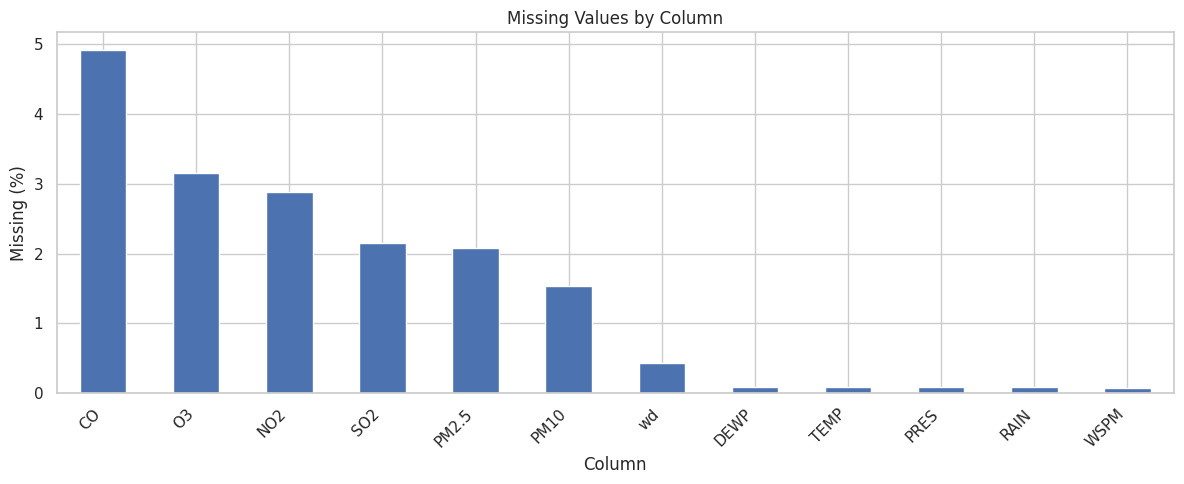

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": air_df.isna().sum(),
    "Missing Percentage": air_df.isna().mean() * 100,
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary.round(2))

columns_with_missing = missing_summary[missing_summary["Missing Count"] > 0]
if not columns_with_missing.empty:
    plt.figure(figsize=(12, 5))
    columns_with_missing["Missing Percentage"].plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.ylabel("Missing (%)")
    plt.xlabel("Column")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in this dataset.")

## 6. Exploratory data analysis: pollutants and stations

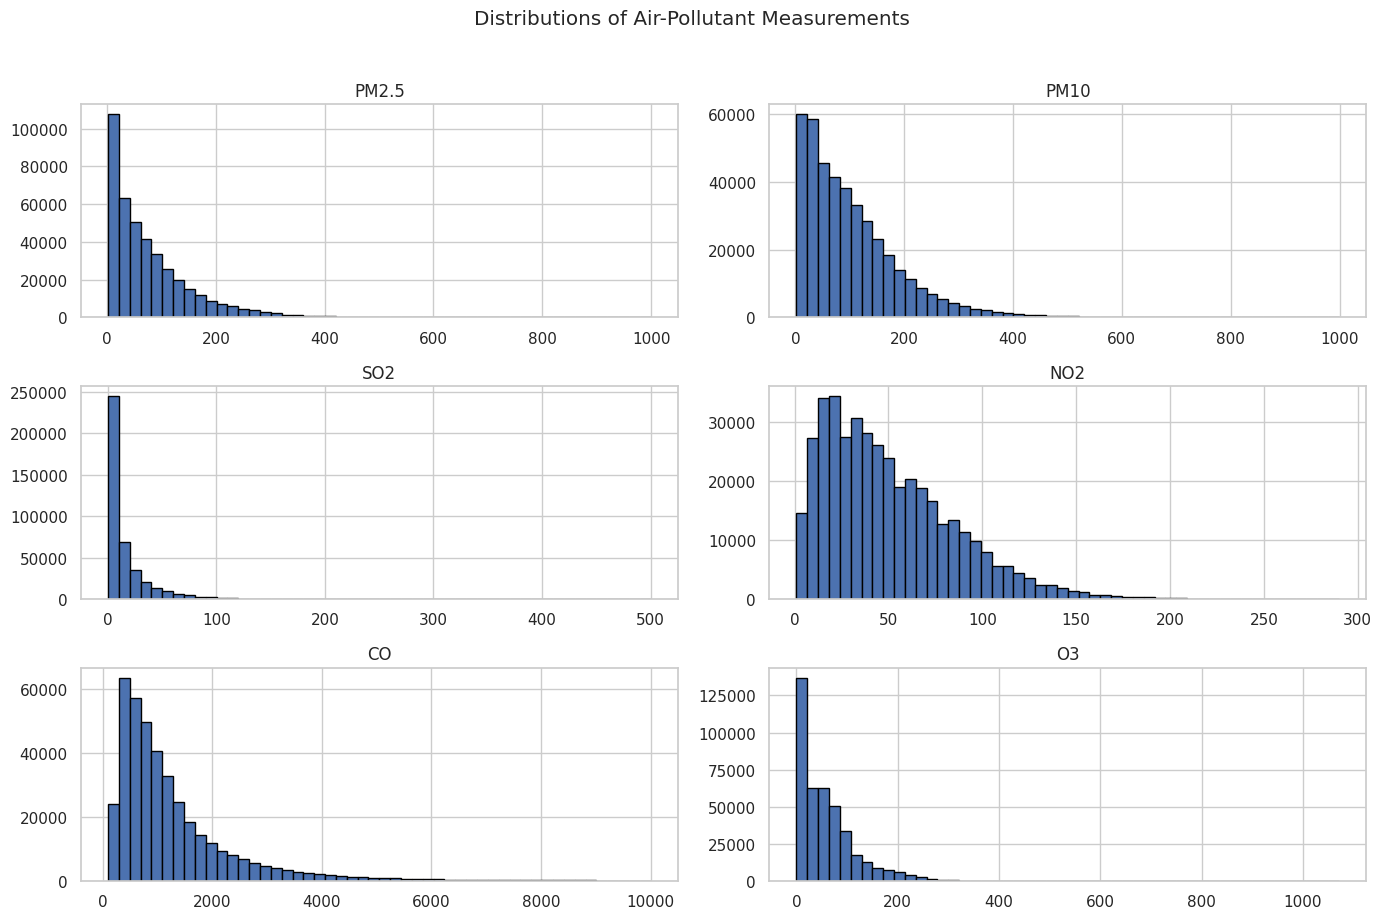

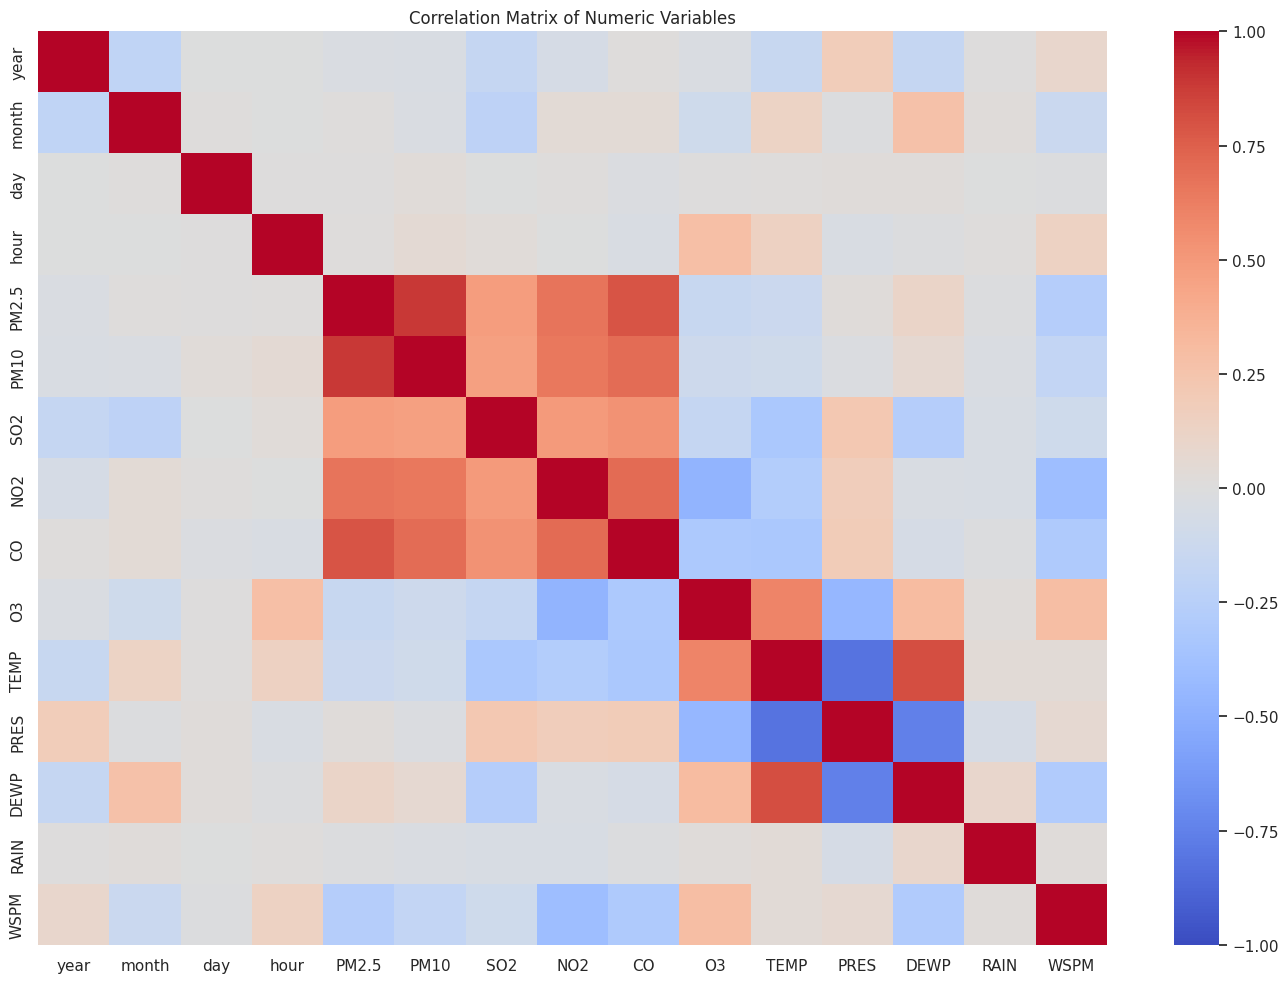

Correlation with current PM2.5:


,correlation
PM2.5,1.000
PM10,0.884
CO,0.790
NO2,0.667
SO2,0.482
DEWP,0.115
PRES,0.019
hour,0.012
month,0.010
day,0.003


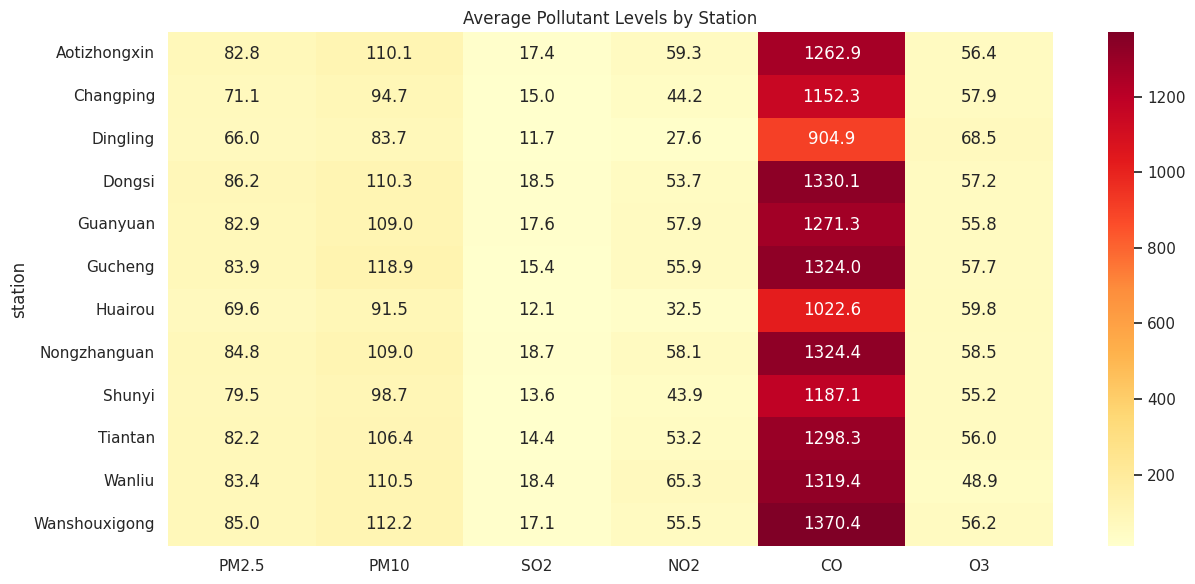

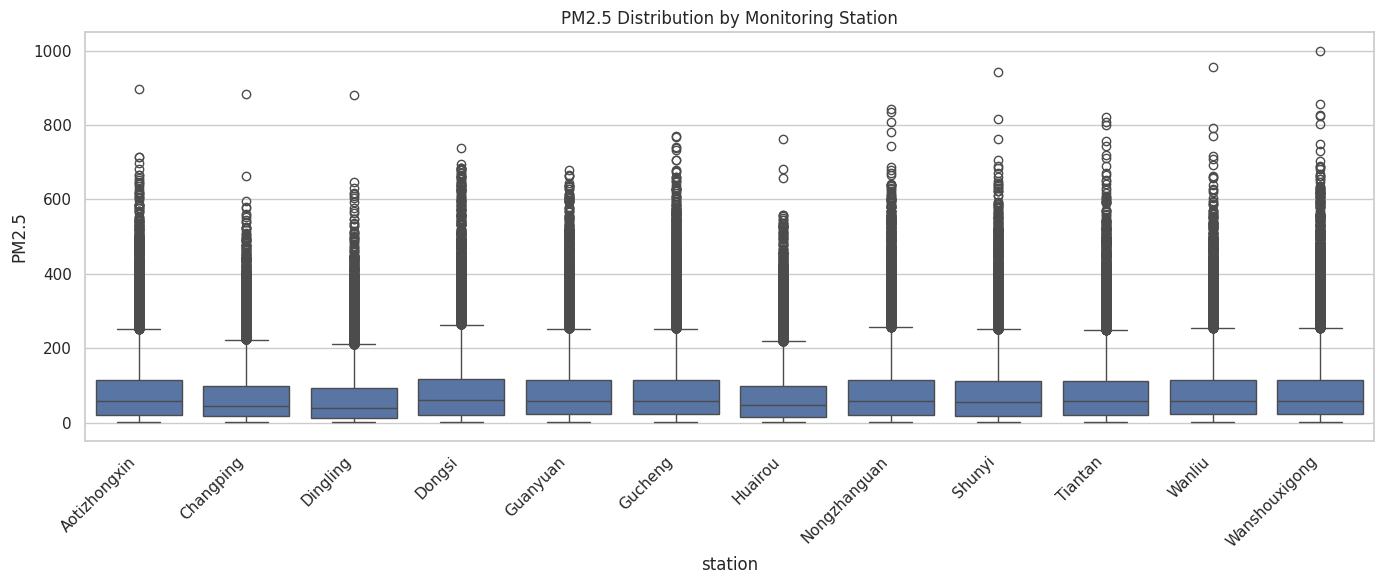

In [ ]:
pollutants = [c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"] if c in air_df.columns]

# Pollutant distributions
air_df[pollutants].hist(figsize=(14, 9), bins=50, edgecolor="black")
plt.suptitle("Distributions of Air-Pollutant Measurements", y=1.02)
plt.tight_layout()
plt.show()

# Correlations are descriptive only; strong correlation does not establish causation.
numeric_df = air_df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()

print("Correlation with current PM2.5:")
display(corr_matrix["PM2.5"].sort_values(ascending=False).to_frame("correlation").round(3))

# Station-level pollutant averages
station_means = air_df.groupby("station")[pollutants].mean()
plt.figure(figsize=(13, 6))
sns.heatmap(station_means, cmap="YlOrRd", annot=True, fmt=".1f")
plt.title("Average Pollutant Levels by Station")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.boxplot(data=air_df, x="station", y="PM2.5")
plt.title("PM2.5 Distribution by Monitoring Station")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Time-series EDA

Inspect hourly changes, daily averages, 24-hour rolling behaviour, and common hour/month patterns for one station. Rolling statistics use current and earlier observations only.

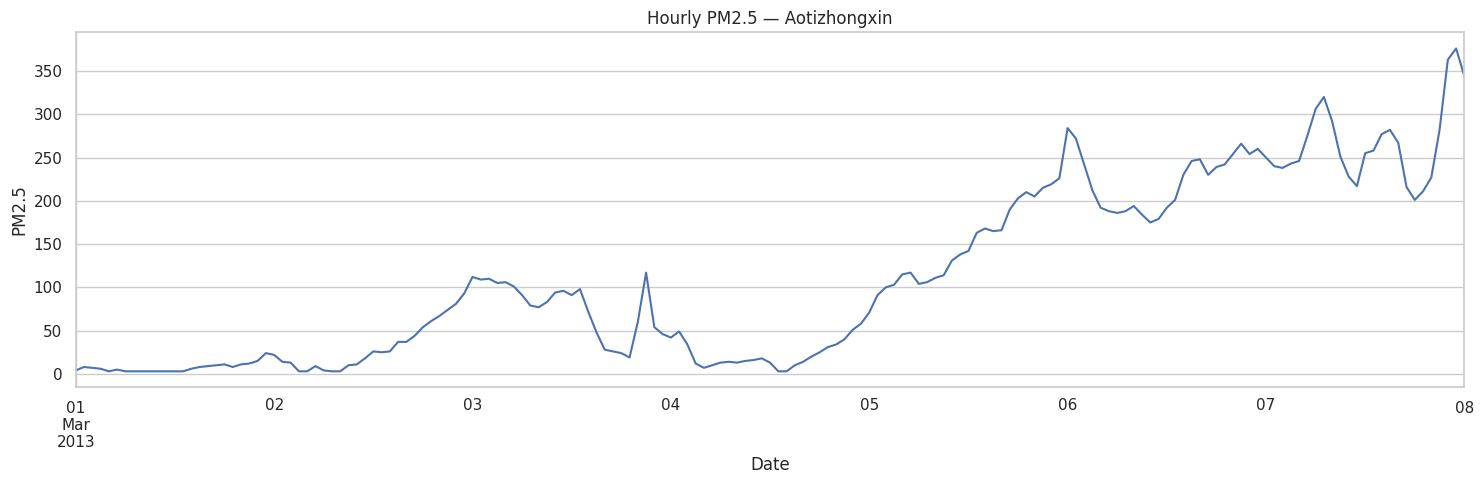

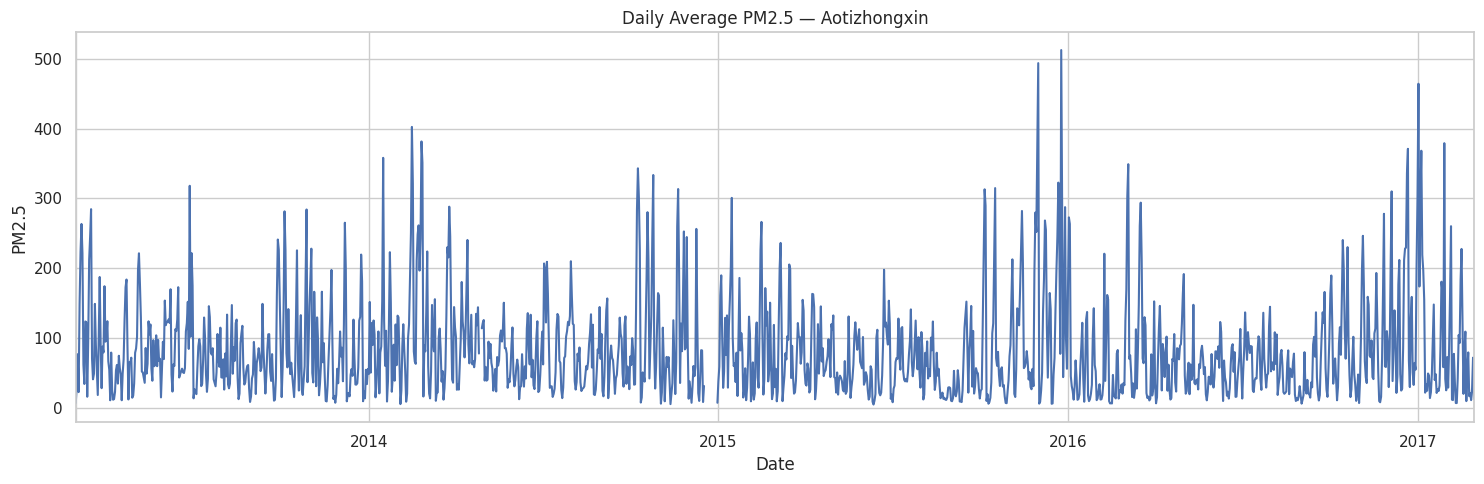

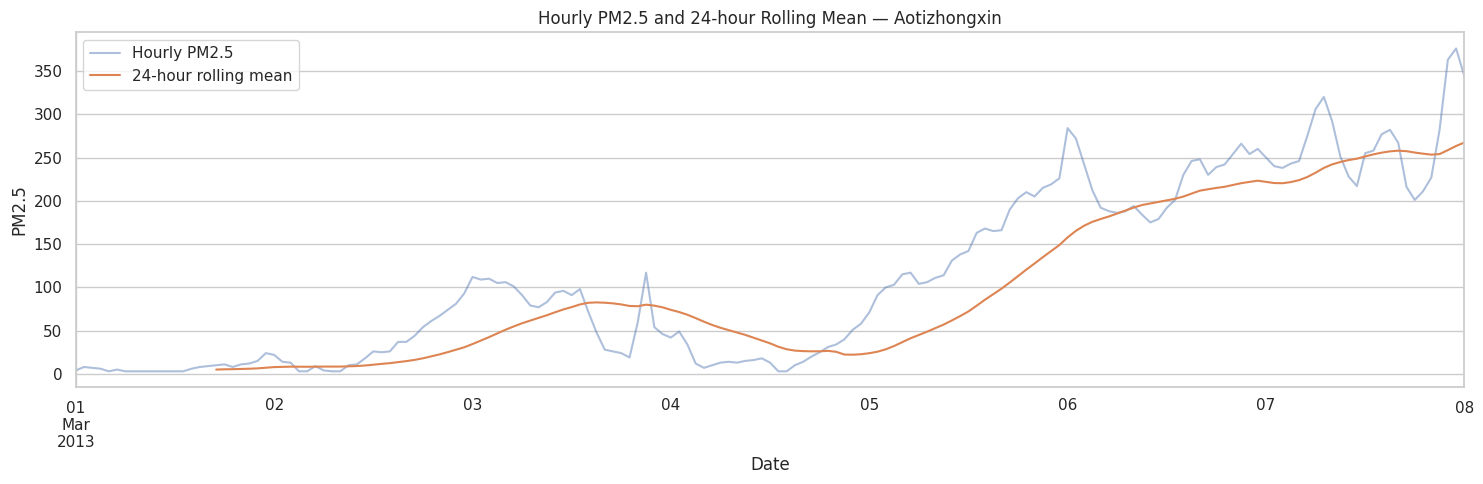

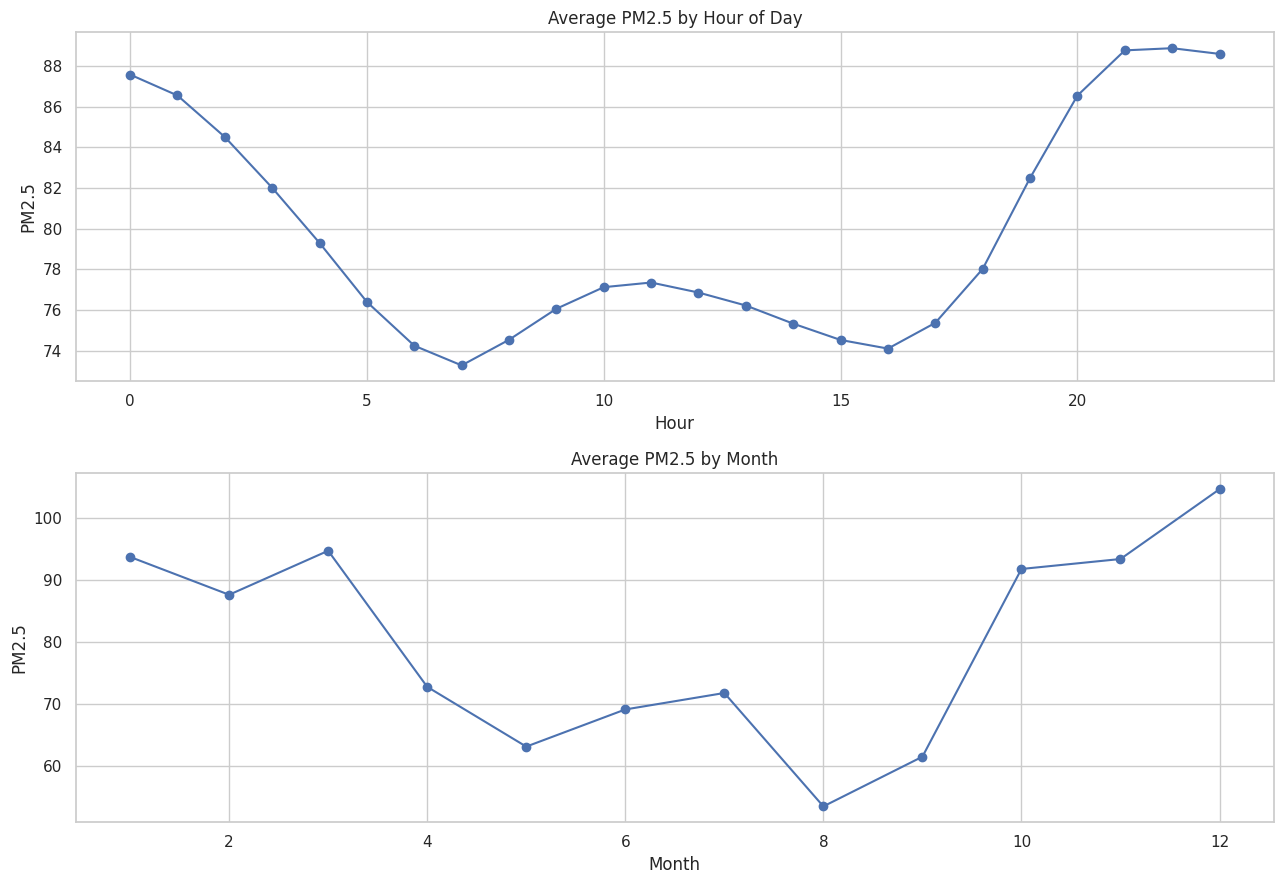

In [ ]:
# Choose a station for the detailed time-series plots.
PLOT_STATION = sorted(air_df["station"].dropna().unique())[0]

station_ts = (
    air_df.loc[air_df["station"] == PLOT_STATION, ["datetime", "PM2.5"]]
    .sort_values("datetime")
    .set_index("datetime")["PM2.5"]
)

# Hourly observations for a short interval so individual changes are visible.
plot_start = station_ts.first_valid_index()
plot_end = plot_start + pd.Timedelta(days=7)
plt.figure(figsize=(15, 5))
station_ts.loc[plot_start:plot_end].plot()
plt.title(f"Hourly PM2.5 — {PLOT_STATION}")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.grid(True)
plt.tight_layout()
plt.show()

# Daily average trend
daily_pm25 = station_ts.resample("D").mean()
plt.figure(figsize=(15, 5))
daily_pm25.plot()
plt.title(f"Daily Average PM2.5 — {PLOT_STATION}")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

# 24-hour rolling average
rolling_24h = station_ts.rolling(window=24, min_periods=18).mean()
plt.figure(figsize=(15, 5))
station_ts.loc[plot_start:plot_end].plot(alpha=0.45, label="Hourly PM2.5")
rolling_24h.loc[plot_start:plot_end].plot(label="24-hour rolling mean")
plt.title(f"Hourly PM2.5 and 24-hour Rolling Mean — {PLOT_STATION}")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

# Average patterns across the full dataset
fig, axes = plt.subplots(2, 1, figsize=(13, 9))
air_df.groupby("hour")["PM2.5"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Average PM2.5 by Hour of Day", xlabel="Hour", ylabel="PM2.5")
air_df.groupby("month")["PM2.5"].mean().reindex(range(1, 13)).plot(ax=axes[1], marker="o")
axes[1].set(title="Average PM2.5 by Month", xlabel="Month", ylabel="PM2.5")
plt.tight_layout()
plt.show()

## 8. Outlier inspection — do not automatically remove extremes

The IQR rule identifies unusual observations; it does not prove they are errors. Genuine pollution episodes should be retained. Values at or above 999 are reported for investigation, not automatically capped or deleted.

In [ ]:
outlier_rows = []
print("Counts at or above 999 (review; do not automatically replace):")
for col in pollutants:
    print(f"{col}: {(air_df[col] >= 999).sum():,}")
    values = air_df[col].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "Feature": col,
        "IQR Lower Bound": lower,
        "IQR Upper Bound": upper,
        "Potential Outliers": n_out,
        "Outlier Percentage": 100 * n_out / len(values),
    })
display(pd.DataFrame(outlier_rows).round(3))
print("Policy: preserve plausible extreme pollution readings. Validate suspicious codes using the dataset documentation before changing data.")

Counts at or above 999 (review; do not automatically replace):
PM2.5: 1
PM10: 3
SO2: 0
NO2: 0
CO: 184,058
O3: 16


,Feature,IQR Lower Bound,IQR Upper Bound,Potential Outliers,Outlier Percentage
0,PM2.5,-116.5,247.5,19142,4.646
1,PM10,-127.5,308.5,14658,3.538
2,SO2,-22.5,45.5,35566,8.638
3,NO2,-49.0,143.0,7021,1.718
4,CO,-1000.0,3000.0,28054,7.012
5,O3,-95.5,188.5,16599,4.073


Policy: preserve plausible extreme pollution readings. Validate suspicious codes using the dataset documentation before changing data.


## 9. Define the forecasting horizon and create the next-hour target

The target is the same station’s PM2.5 reading exactly one hour after the current observation.

In [ ]:
# ==========================================
# NEXT-HOUR TARGET CREATION
# ==========================================

HORIZON_HOURS = 1
TARGET = f"PM2.5_next_{HORIZON_HOURS}h"

if HORIZON_HOURS != 1:
    raise ValueError("This notebook is configured for next-hour forecasting.")

target_df = (
    air_df.sort_values(["station", "datetime"])
    .reset_index(drop=True)
    .copy()
)

grouped = target_df.groupby("station", sort=False)

# At time t, target is PM2.5 from the same station at exactly t + 1 hour.
target_df["target_datetime"] = grouped["datetime"].shift(-HORIZON_HOURS)
target_df[TARGET] = grouped["PM2.5"].shift(-HORIZON_HOURS)

exact_target_time = (
    target_df["target_datetime"]
    == target_df["datetime"] + pd.Timedelta(hours=HORIZON_HOURS)
)
target_df.loc[~exact_target_time, TARGET] = np.nan

# Verify target values against the original source row at target_datetime.
future_lookup = air_df[["station", "datetime", "PM2.5"]].rename(
    columns={
        "datetime": "target_datetime",
        "PM2.5": "source_future_PM25"
    }
)

target_check = target_df.loc[
    target_df[TARGET].notna(),
    ["station", "datetime", "target_datetime", TARGET]
].merge(
    future_lookup,
    on=["station", "target_datetime"],
    how="left",
    validate="many_to_one"
)

unmatched_targets = int(target_check["source_future_PM25"].isna().sum())

if target_check.empty:
    target_mismatches = 0
else:
    target_mismatches = int(
        (~np.isclose(
            target_check[TARGET].to_numpy(dtype=float),
            target_check["source_future_PM25"].to_numpy(dtype=float),
            equal_nan=False
        )).sum()
    )

print("Forecast horizon:", HORIZON_HOURS, "hour")
print("Target column:", TARGET)
print("Source rows:", len(target_df))
print("Valid non-missing next-hour targets:", int(target_df[TARGET].notna().sum()))
print("Missing targets:", int(target_df[TARGET].isna().sum()))
print("Targets without matching source readings:", unmatched_targets)
print("Target mismatches:", target_mismatches)

if unmatched_targets or target_mismatches:
    raise ValueError("Target verification failed. Check station/time alignment.")

print("SUCCESS: next-hour target timestamps and values are correctly aligned.")
display(
    target_df[
        ["station", "datetime", "PM2.5", "target_datetime", TARGET]
    ].head(12)
)


Forecast horizon: 1 hour
Target column: PM2.5_next_1h
Source rows: 420768
Valid non-missing next-hour targets: 412017
Missing targets: 8751
Targets without matching source readings: 0
Target mismatches: 0
SUCCESS: next-hour target timestamps and values are correctly aligned.


,station,datetime,PM2.5,target_datetime,PM2.5_next_1h
0,Aotizhongxin,2013-03-01 00:00:00,4.0,2013-03-01 01:00:00,8.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0,2013-03-01 02:00:00,7.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0,2013-03-01 03:00:00,6.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0,2013-03-01 04:00:00,3.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0,2013-03-01 05:00:00,5.0
5,Aotizhongxin,2013-03-01 05:00:00,5.0,2013-03-01 06:00:00,3.0
6,Aotizhongxin,2013-03-01 06:00:00,3.0,2013-03-01 07:00:00,3.0
7,Aotizhongxin,2013-03-01 07:00:00,3.0,2013-03-01 08:00:00,3.0
8,Aotizhongxin,2013-03-01 08:00:00,3.0,2013-03-01 09:00:00,3.0
9,Aotizhongxin,2013-03-01 09:00:00,3.0,2013-03-01 10:00:00,3.0


## 10. Feature engineering: historical lags, rolling statistics and calendar features

Lag and rolling predictors are calculated within each station using only current and earlier PM2.5 observations. Target-time calendar features are permissible because the next hour’s calendar is known at forecast time. Current pollutant/weather measurements are assumed to be available at prediction time.

In [ ]:
# ==========================================
# FEATURE ENGINEERING FOR NEXT-HOUR FORECASTING
# ==========================================

feature_df = target_df.copy()
feature_df = feature_df.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

# Historical PM2.5 lags. Keep only exact timestamp matches.
# These values are known at the current observation time.
LAGS = [1, 2, 3, 6, 12, 24, 48, 72, 168]

for lag in LAGS:
    lag_col = f"PM2.5_lag_{lag}h"

    station_group = feature_df.groupby("station", sort=False)
    lag_values = station_group["PM2.5"].shift(lag)
    prior_time = station_group["datetime"].shift(lag)

    exact_lag_time = (
        feature_df["datetime"] - prior_time
    ) == pd.Timedelta(hours=lag)

    feature_df[lag_col] = lag_values.where(exact_lag_time)

# Rolling statistics use current and past readings only (never future readings).
ROLLING_WINDOWS = [3, 6, 12, 24, 72]

for window in ROLLING_WINDOWS:
    min_periods = max(2, window // 2)

    feature_df[f"PM2.5_rolling_mean_{window}h"] = (
        feature_df.groupby("station", sort=False)["PM2.5"]
        .transform(
            lambda s: s.rolling(
                window=window,
                min_periods=min_periods
            ).mean()
        )
    )

    feature_df[f"PM2.5_rolling_std_{window}h"] = (
        feature_df.groupby("station", sort=False)["PM2.5"]
        .transform(
            lambda s: s.rolling(
                window=window,
                min_periods=min_periods
            ).std()
        )
    )

# Calendar features at the current observation time.
feature_df["hour_sin"] = np.sin(
    2 * np.pi * feature_df["hour"] / 24
)
feature_df["hour_cos"] = np.cos(
    2 * np.pi * feature_df["hour"] / 24
)
feature_df["month_sin"] = np.sin(
    2 * np.pi * (feature_df["month"] - 1) / 12
)
feature_df["month_cos"] = np.cos(
    2 * np.pi * (feature_df["month"] - 1) / 12
)
feature_df["day_of_week"] = feature_df["datetime"].dt.dayofweek
feature_df["is_weekend"] = (
    feature_df["day_of_week"] >= 5
).astype(int)

# Future calendar information is known at prediction time.
feature_df["target_hour"] = feature_df["target_datetime"].dt.hour
feature_df["target_day_of_week"] = feature_df["target_datetime"].dt.dayofweek
feature_df["target_month"] = feature_df["target_datetime"].dt.month
feature_df["target_year"] = feature_df["target_datetime"].dt.year
feature_df["target_month_sin"] = np.sin(
    2 * np.pi * (feature_df["target_month"] - 1) / 12
)
feature_df["target_month_cos"] = np.cos(
    2 * np.pi * (feature_df["target_month"] - 1) / 12
)
feature_df["target_is_weekend"] = (
    feature_df["target_day_of_week"] >= 5
).astype(int)

# Keep rows with valid future targets. Predictor missingness is handled by the train-fitted imputer.
model_df = feature_df.dropna(
    subset=[TARGET, "target_datetime"]
).copy()

model_df = model_df.sort_values(
    ["target_datetime", "station"]
).reset_index(drop=True)

print("Forecast modelling dataset shape:", model_df.shape)
print("Forecast target:", TARGET)
print("Target missing after filtering:", model_df[TARGET].isna().sum())

lag_columns = [f"PM2.5_lag_{lag}h" for lag in LAGS]
print("Missing lag values (these are imputed using training data only):")
display(model_df[lag_columns].isna().sum().to_frame("missing_count"))

display(
    model_df[
        ["station", "datetime", "PM2.5"]
        + lag_columns
        + ["target_datetime", TARGET]
    ].head(12)
)


Forecast modelling dataset shape: (412017, 52)
Forecast target: PM2.5_next_1h
Target missing after filtering: 0
Missing lag values (these are imputed using training data only):


,missing_count
PM2.5_lag_1h,3845
PM2.5_lag_2h,4161
PM2.5_lag_3h,4636
PM2.5_lag_6h,5262
PM2.5_lag_12h,6081
PM2.5_lag_24h,7126
PM2.5_lag_48h,8074
PM2.5_lag_72h,8632
PM2.5_lag_168h,10226


,station,datetime,PM2.5,PM2.5_lag_1h,PM2.5_lag_2h,PM2.5_lag_3h,PM2.5_lag_6h,PM2.5_lag_12h,PM2.5_lag_24h,PM2.5_lag_48h,PM2.5_lag_72h,PM2.5_lag_168h,target_datetime,PM2.5_next_1h
0,Aotizhongxin,2013-03-01,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,8.0
1,Changping,2013-03-01,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,3.0
2,Dingling,2013-03-01,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,7.0
3,Dongsi,2013-03-01,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
4,Guanyuan,2013-03-01,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
5,Gucheng,2013-03-01,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,6.0
6,Huairou,2013-03-01,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
7,Nongzhanguan,2013-03-01,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,8.0
8,Shunyi,2013-03-01,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,12.0
9,Tiantan,2013-03-01,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,6.0


## 11. Chronological train, validation and test split

Split by `target_datetime`, so all stations for the same forecast timestamp remain in the same partition. The test period is held out until final evaluation.

In [ ]:
# Split by target time (the time of the value being predicted).
# These date boundaries are retained from the previous experiment for comparability.
TRAIN_END = pd.Timestamp("2016-01-01 00:00:00")
VALIDATION_END = pd.Timestamp("2016-09-01 00:00:00")

train_df = model_df[
    model_df["target_datetime"] < TRAIN_END
].copy()

val_df = model_df[
    (model_df["target_datetime"] >= TRAIN_END)
    & (model_df["target_datetime"] < VALIDATION_END)
].copy()

test_df = model_df[
    model_df["target_datetime"] >= VALIDATION_END
].copy()

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for split_name, part in splits.items():
    print(
        f"{split_name}: {len(part):,} rows | "
        f"{part['target_datetime'].min()} to "
        f"{part['target_datetime'].max()} | "
        f"stations={part['station'].nunique()}"
    )

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("One or more splits are empty. Check the date boundaries.")

assert train_df["target_datetime"].max() < val_df["target_datetime"].min()
assert val_df["target_datetime"].max() < test_df["target_datetime"].min()

print("Chronological split checks passed.")

print("\nRows per station:")
display(
    pd.DataFrame({
        "Train": train_df.groupby("station").size(),
        "Validation": val_df.groupby("station").size(),
        "Test": test_df.groupby("station").size(),
    }).fillna(0).astype(int)
)


Train: 292,138 rows | 2013-03-01 01:00:00 to 2015-12-31 23:00:00 | stations=12
Validation: 68,816 rows | 2016-01-01 00:00:00 to 2016-08-31 23:00:00 | stations=12
Test: 51,063 rows | 2016-09-01 00:00:00 to 2017-02-28 23:00:00 | stations=12
Chronological split checks passed.

Rows per station:


,Train,Validation,Test
station,,,
Aotizhongxin,24131,5715,4292
Changping,24217,5775,4297
Dingling,24399,5742,4143
Dongsi,24496,5583,4234
Guanyuan,24440,5759,4248
Gucheng,24382,5784,4251
Huairou,24082,5748,4280
Nongzhanguan,24381,5794,4260
Shunyi,24286,5654,4210


## 12. Select model inputs and preprocess without leakage

The target and timestamps are excluded from raw input columns. Imputation, scaling and one-hot encoding are fitted on training data only; validation and test are transformed using the training-fitted preprocessor.

In [ ]:
# ==========================================
# SELECT FEATURES AND PREPROCESS WITHOUT LEAKAGE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Never expose target values or timestamps as raw model inputs.
EXCLUDE_FROM_X = [TARGET, "target_datetime", "datetime"]
feature_columns = [
    col for col in model_df.columns
    if col not in EXCLUDE_FROM_X
]

# Check for accidental target leakage.
leakage_columns = [
    col for col in feature_columns
    if "next" in col.lower()
]

print("Potential target leakage columns:", leakage_columns)

if leakage_columns:
    raise ValueError(
        f"Potential future target information found in X: {leakage_columns}"
    )

assert TARGET not in feature_columns
assert "target_datetime" not in feature_columns
assert "datetime" not in feature_columns

# Separate X and y.
X_train = train_df[feature_columns].copy()
y_train = pd.to_numeric(train_df[TARGET], errors="coerce").astype("float64")

X_val = val_df[feature_columns].copy()
y_val = pd.to_numeric(val_df[TARGET], errors="coerce").astype("float64")

X_test = test_df[feature_columns].copy()
y_test = pd.to_numeric(test_df[TARGET], errors="coerce").astype("float64")

# Identify numeric and categorical predictors from training data.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Number of input columns:", len(feature_columns))
print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)
print("Target:", TARGET)

# Convert pandas nullable values (pd.NA) to NumPy-compatible np.nan.
# Apply the exact same column typing to train, validation and test.
for frame in [X_train, X_val, X_test]:
    for col in numeric_features:
        frame[col] = pd.to_numeric(
            frame[col],
            errors="coerce"
        ).astype("float64")

    for col in categorical_features:
        frame[col] = frame[col].astype("object")
        frame[col] = frame[col].where(frame[col].notna(), np.nan)

# Check targets before fitting.
for split_name, target_values in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    if not np.isfinite(target_values.to_numpy()).all():
        raise ValueError(
            f"Missing or infinite target values found in {split_name}."
        )
    print(f"{split_name} target rows: {len(target_values):,}")

# Support older and newer scikit-learn versions.
try:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", one_hot_encoder),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop"
)

# Fit only on training data; validation and test are transform-only.
X_train_processed = np.asarray(
    preprocessor.fit_transform(X_train),
    dtype=np.float32
)
X_val_processed = np.asarray(
    preprocessor.transform(X_val),
    dtype=np.float32
)
X_test_processed = np.asarray(
    preprocessor.transform(X_test),
    dtype=np.float32
)

for name, values in [
    ("Train", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed),
]:
    print(
        f"{name} matrix: {values.shape}; "
        f"missing={np.isnan(values).sum():,}; "
        f"infinite={np.isinf(values).sum():,}"
    )
    if not np.isfinite(values).all():
        raise ValueError(
            f"Non-finite model inputs remain in {name} data."
        )

print("Target vector shapes:", y_train.shape, y_val.shape, y_test.shape)
print("Preprocessing completed successfully.")


Potential target leakage columns: []
Number of input columns: 49
Numeric features: 47
Categorical features: ['wd', 'station']
Target: PM2.5_next_1h
Train target rows: 292,138
Validation target rows: 68,816
Test target rows: 51,063
Train matrix: (292138, 75); missing=0; infinite=0
Validation matrix: (68816, 75); missing=0; infinite=0
Test matrix: (51063, 75); missing=0; infinite=0
Target vector shapes: (292138,) (68816,) (51063,)
Preprocessing completed successfully.


## 13. Evaluation metrics and next-hour naive baseline

The naive baseline predicts next-hour PM2.5 by carrying forward the current PM2.5 measurement. For fair comparisons, score the baseline and model on identical rows where current PM2.5 is available.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

baseline_mask_val = val_df["PM2.5"].notna()
baseline_validation = regression_metrics(
    val_df.loc[baseline_mask_val, TARGET],
    val_df.loc[baseline_mask_val, "PM2.5"]
)
baseline_validation["Model"] = "Naive baseline (current PM2.5)"
baseline_validation["Rows scored"] = int(baseline_mask_val.sum())

print("Validation baseline results:")
display(pd.DataFrame([baseline_validation]).set_index("Model").round(4))

Validation baseline results:


,MAE,RMSE,R2,Rows scored
Model,,,,
Naive baseline (current PM2.5),9.0129,17.6277,0.9245,68176


## 14. Train and compare machine-learning models

Compare Linear Regression, Ridge, Random Forest, Extra Trees and Histogram Gradient Boosting. Metrics in the main comparison use non-negative forecasts. Model selection is based on validation RMSE, not test performance.

In [ ]:
# ==========================================
# TRAIN AND COMPARE FORECASTING MODELS
# ==========================================

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

model_templates = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=10.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=120,
        max_depth=20,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=120,
        max_depth=20,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
}

fitted_models = {}
validation_predictions_by_model = {}
model_rows = []

for model_name, model in model_templates.items():
    print(f"Training {model_name}...")
    start_time = time.time()

    model.fit(X_train_processed, y_train)

    raw_prediction = np.asarray(
        model.predict(X_val_processed),
        dtype=float
    )
    clipped_prediction = np.maximum(raw_prediction, 0)

    validation_predictions_by_model[model_name] = {
        "raw": raw_prediction,
        "clipped": clipped_prediction,
    }

    raw_metrics = regression_metrics(y_val, raw_prediction)
    clipped_metrics = regression_metrics(y_val, clipped_prediction)

    model_rows.append({
        "Model": model_name,
        "MAE": clipped_metrics["MAE"],
        "RMSE": clipped_metrics["RMSE"],
        "R2": clipped_metrics["R2"],
        "Raw_MAE": raw_metrics["MAE"],
        "Raw_RMSE": raw_metrics["RMSE"],
        "Raw_R2": raw_metrics["R2"],
        "Negative_Raw_Predictions": int((raw_prediction < 0).sum()),
        "Rows scored": len(y_val),
        "Training seconds": round(time.time() - start_time, 2),
    })

    fitted_models[model_name] = model

    print(
        f"{model_name} completed | "
        f"Clipped validation RMSE: {clipped_metrics['RMSE']:.4f}"
    )

# The main MAE/RMSE/R2 columns use non-negative predictions.
model_comparison = (
    pd.DataFrame(model_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nVALIDATION MODEL COMPARISON")
display(model_comparison.round(4))


Training Linear Regression...
Linear Regression completed | Clipped validation RMSE: 18.2035
Training Ridge Regression...
Ridge Regression completed | Clipped validation RMSE: 18.2093
Training Random Forest...
Random Forest completed | Clipped validation RMSE: 17.8591
Training Extra Trees...
Extra Trees completed | Clipped validation RMSE: 17.7080
Training Histogram Gradient Boosting...
Histogram Gradient Boosting completed | Clipped validation RMSE: 17.9741

VALIDATION MODEL COMPARISON


,Model,MAE,RMSE,R2,Raw_MAE,Raw_RMSE,Raw_R2,Negative_Raw_Predictions,Rows scored,Training seconds
0,Extra Trees,8.6955,17.7080,0.9240,8.6955,17.7080,0.9240,0,68816,80.86
1,Random Forest,8.7897,17.8591,0.9227,8.7897,17.8591,0.9227,0,68816,281.07
2,Histogram Gradient Boosting,8.7981,17.9741,0.9217,8.7988,17.9749,0.9217,4,68816,7.86
3,Linear Regression,9.5524,18.2035,0.9197,9.6455,18.2728,0.9191,1716,68816,0.83
4,Ridge Regression,9.5557,18.2093,0.9197,9.6506,18.2799,0.9190,1729,68816,0.12


## 15. Compare models with the naive baseline and select a validation winner

All candidates and the naive baseline are compared on the same validation observations. The winning model is selected using the overall validation RMSE.

In [ ]:
# ==========================================
# COMPARE MODELS WITH A NAIVE BASELINE
# VALIDATION DATA ONLY
# ==========================================

# Naive baseline: predict next-hour PM2.5 using current PM2.5.
baseline_mask_val = val_df["PM2.5"].notna()

baseline_validation = regression_metrics(
    val_df.loc[baseline_mask_val, TARGET],
    val_df.loc[baseline_mask_val, "PM2.5"]
)
baseline_validation["Model"] = "Naive baseline (current PM2.5)"
baseline_validation["Rows scored"] = int(baseline_mask_val.sum())

# Score every candidate on the same rows as the naive baseline.
fair_validation_rows = [baseline_validation]

for model_name in model_templates:
    predictions = validation_predictions_by_model[model_name]["clipped"]
    same_rows_predictions = predictions[baseline_mask_val.to_numpy()]
    same_rows_actual = y_val.loc[baseline_mask_val]

    metrics = regression_metrics(
        same_rows_actual,
        same_rows_predictions
    )
    metrics["Model"] = model_name
    metrics["Rows scored"] = int(baseline_mask_val.sum())
    fair_validation_rows.append(metrics)

comparison_with_baseline = (
    pd.DataFrame(fair_validation_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("FAIR VALIDATION COMPARISON — SAME OBSERVATIONS")
display(comparison_with_baseline.set_index("Model").round(4))

# Select winner by overall clipped validation RMSE.
best_model_name = model_comparison.iloc[0]["Model"]

print("\nBest model by clipped validation RMSE:", best_model_name)
print(
    "Best clipped validation RMSE:",
    round(float(model_comparison.iloc[0]["RMSE"]), 4)
)

best_vs_baseline = comparison_with_baseline[
    comparison_with_baseline["Model"].isin([
        "Naive baseline (current PM2.5)",
        best_model_name
    ])
]
print("\nSelected model versus naive baseline:")
display(best_vs_baseline.set_index("Model").round(4))


FAIR VALIDATION COMPARISON — SAME OBSERVATIONS


,MAE,RMSE,R2,Rows scored
Model,,,,
Linear Regression,9.1943,16.8994,0.9306,68176
Ridge Regression,9.2010,16.9239,0.9304,68176
Extra Trees,8.5188,17.0707,0.9292,68176
Random Forest,8.6100,17.2076,0.9280,68176
Histogram Gradient Boosting,8.5917,17.3240,0.9270,68176
Naive baseline (current PM2.5),9.0129,17.6277,0.9245,68176



Best model by clipped validation RMSE: Extra Trees
Best clipped validation RMSE: 17.708

Selected model versus naive baseline:


,MAE,RMSE,R2,Rows scored
Model,,,,
Extra Trees,8.5188,17.0707,0.9292,68176
Naive baseline (current PM2.5),9.0129,17.6277,0.9245,68176


## 16. Feature-selection experiment (validation only)

Use `SelectKBest(f_regression)` to test different feature counts. The selector is fitted only on the training partition and applied to validation. Choose the feature count using validation RMSE. This is a univariate linear F-test filter; it is a useful baseline selector but may not capture every nonlinear relationship.

In [ ]:

# ==========================================
# FEATURE SELECTION EXPERIMENT
# ==========================================

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.base import clone

# Number of available processed features
total_features = X_train_processed.shape[1]

# Different feature counts to experiment with
k_values = [k for k in [10, 20, 30, 40, 50, total_features] if k <= total_features]

# Remove duplicate or invalid values
k_values = sorted(
    set(min(k, total_features) for k in k_values)
)

feature_selection_results = []

selectors = {}
feature_models = {}

print("Original number of features:", total_features)
print("Selected model:", best_model_name)


# ==========================================
# TRAIN AND VALIDATE WITH DIFFERENT FEATURES
# ==========================================

for k in k_values:

    print(f"\nTesting top {k} features...")

    # Feature selector
    selector = SelectKBest(
        score_func=f_regression,
        k=k
    )

    # Fit selector ONLY on training data
    X_train_selected = selector.fit_transform(
        X_train_processed,
        y_train
    )

    # Apply same selection to validation data
    X_val_selected = selector.transform(
        X_val_processed
    )

    # Train the previously selected best model
    model = clone(
        model_templates[best_model_name]
    )

    model.fit(
        X_train_selected,
        y_train
    )

    # Validation predictions
    val_predictions = model.predict(
        X_val_selected
    )

    # Non-negative prediction constraint
    val_predictions = np.maximum(
        val_predictions, 0
    )

    # Calculate validation metrics
    metrics = regression_metrics(
        y_val,
        val_predictions
    )

    metrics["Number of Features"] = k
    metrics["Model"] = best_model_name

    feature_selection_results.append(metrics)

    selectors[k] = selector
    feature_models[k] = model

    print(
        f"Features: {k} | "
        f"MAE: {metrics['MAE']:.4f} | "
        f"RMSE: {metrics['RMSE']:.4f} | "
        f"R2: {metrics['R2']:.4f}"
    )


# ==========================================
# COMPARE FEATURE COUNTS
# ==========================================

feature_selection_comparison = pd.DataFrame(
    feature_selection_results
).sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nFEATURE SELECTION COMPARISON")

display(
    feature_selection_comparison.round(4)
)


# ==========================================
# IDENTIFY BEST FEATURE COUNT
# ==========================================

best_feature_row = (
    feature_selection_comparison.iloc[0]
)

best_k = int(
    best_feature_row["Number of Features"]
)

best_feature_selector = selectors[best_k]
best_feature_model = feature_models[best_k]

print("\nBest number of features:", best_k)

print(
    "Best validation RMSE:",
    round(best_feature_row["RMSE"], 4)
)


# ==========================================
# SHOW SELECTED FEATURE NAMES
# ==========================================

transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

selected_feature_names = (
    transformed_feature_names[
        best_feature_selector.get_support()
    ]
)

print("\nSELECTED FEATURES:")

for feature in selected_feature_names:
    print(feature)


Original number of features: 75
Selected model: Extra Trees

Testing top 10 features...
Features: 10 | MAE: 8.8750 | RMSE: 18.0153 | R2: 0.9214

Testing top 20 features...
Features: 20 | MAE: 8.8681 | RMSE: 18.0447 | R2: 0.9211

Testing top 30 features...
Features: 30 | MAE: 8.7314 | RMSE: 17.6297 | R2: 0.9247

Testing top 40 features...
Features: 40 | MAE: 8.7144 | RMSE: 17.7224 | R2: 0.9239

Testing top 50 features...
Features: 50 | MAE: 8.7284 | RMSE: 17.6819 | R2: 0.9242

Testing top 75 features...
Features: 75 | MAE: 8.6955 | RMSE: 17.7080 | R2: 0.9240

FEATURE SELECTION COMPARISON


,MAE,RMSE,R2,Number of Features,Model
0,8.7314,17.6297,0.9247,30,Extra Trees
1,8.7284,17.6819,0.9242,50,Extra Trees
2,8.6955,17.7080,0.9240,75,Extra Trees
3,8.7144,17.7224,0.9239,40,Extra Trees
4,8.8750,18.0153,0.9214,10,Extra Trees
5,8.8681,18.0447,0.9211,20,Extra Trees



Best number of features: 30
Best validation RMSE: 17.6297

SELECTED FEATURES:
numeric__PM2.5
numeric__PM10
numeric__SO2
numeric__NO2
numeric__CO
numeric__O3
numeric__TEMP
numeric__DEWP
numeric__WSPM
numeric__PM2.5_lag_1h
numeric__PM2.5_lag_2h
numeric__PM2.5_lag_3h
numeric__PM2.5_lag_6h
numeric__PM2.5_lag_12h
numeric__PM2.5_lag_24h
numeric__PM2.5_lag_48h
numeric__PM2.5_rolling_mean_3h
numeric__PM2.5_rolling_std_3h
numeric__PM2.5_rolling_mean_6h
numeric__PM2.5_rolling_std_6h
numeric__PM2.5_rolling_mean_12h
numeric__PM2.5_rolling_std_12h
numeric__PM2.5_rolling_mean_24h
numeric__PM2.5_rolling_std_24h
numeric__PM2.5_rolling_mean_72h
numeric__PM2.5_rolling_std_72h
numeric__month_cos
numeric__target_month_cos
categorical__wd_NNW
categorical__wd_NW


## 17. Compare all features with selected features on validation

This comparison describes the validation results only. The 30-feature (or whichever `best_k` is selected) model is carried forward based on validation RMSE.

In [ ]:
# ==========================================
# FULL FEATURES VS SELECTED FEATURES
# ==========================================

original_best_result = model_comparison[
    model_comparison["Model"] == best_model_name
].iloc[0]

selected_best_result = feature_selection_comparison.iloc[0]

comparison_summary = pd.DataFrame([
    {
        "Experiment": "All features",
        "Number of Features": total_features,
        "MAE": original_best_result["MAE"],
        "RMSE": original_best_result["RMSE"],
        "R2": original_best_result["R2"]
    },
    {
        "Experiment": "Selected features",
        "Number of Features": best_k,
        "MAE": selected_best_result["MAE"],
        "RMSE": selected_best_result["RMSE"],
        "R2": selected_best_result["R2"]
    }
])

display(comparison_summary.round(4))

,Experiment,Number of Features,MAE,RMSE,R2
0,All features,75,8.6955,17.7080,0.9240
1,Selected features,30,8.7314,17.6297,0.9247


Selected-feature validation metrics:


,MAE,RMSE,R2
0,8.7314,17.6297,0.9247


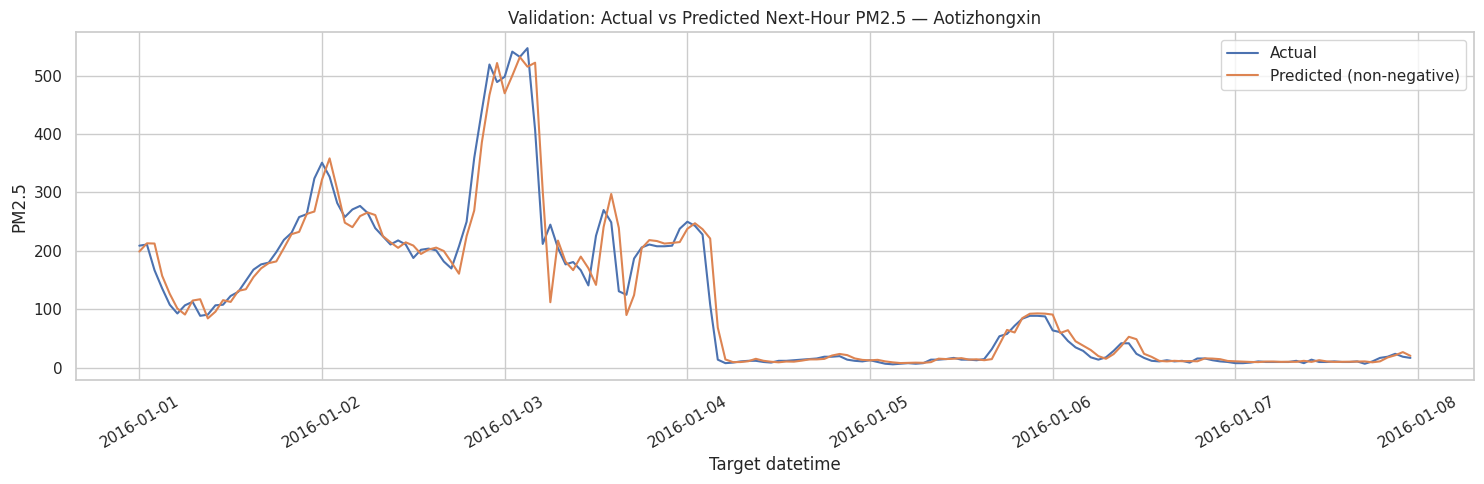

In [ ]:
# ==========================================
# VALIDATION DIAGNOSTICS FOR THE SELECTED-FEATURE MODEL
# ==========================================

validation_selected_features = best_feature_selector.transform(X_val_processed)
validation_selected_raw = np.asarray(
    best_feature_model.predict(validation_selected_features), dtype=float
)
validation_selected_clipped = np.maximum(validation_selected_raw, 0)

selected_validation_metrics = regression_metrics(
    y_val, validation_selected_clipped
)
print("Selected-feature validation metrics:")
display(pd.DataFrame([selected_validation_metrics]).round(4))

validation_diag_df = val_df[["station", "target_datetime", TARGET]].copy().reset_index(drop=True)
validation_diag_df["prediction"] = validation_selected_clipped
validation_diag_df["residual"] = (
    validation_diag_df[TARGET] - validation_diag_df["prediction"]
)

PLOT_STATION = sorted(validation_diag_df["station"].unique())[0]
validation_station_plot = (
    validation_diag_df[validation_diag_df["station"] == PLOT_STATION]
    .sort_values("target_datetime")
    .head(24 * 7)
)

plt.figure(figsize=(15, 5))
plt.plot(validation_station_plot["target_datetime"], validation_station_plot[TARGET], label="Actual")
plt.plot(validation_station_plot["target_datetime"], validation_station_plot["prediction"], label="Predicted (non-negative)")
plt.title(f"Validation: Actual vs Predicted Next-Hour PM2.5 — {PLOT_STATION}")
plt.xlabel("Target datetime")
plt.ylabel("PM2.5")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 18. Feature importance on validation data

Permutation importance estimates how much validation RMSE worsens when a selected input column is shuffled. It is descriptive, not causal. A deterministic validation sample is used to keep computation manageable.

Permutation importance (validation sample):


,Feature,Importance,Importance_Std
0,numeric__PM2.5,33.58893,0.37139
1,numeric__PM10,5.10528,0.19331
2,numeric__PM2.5_rolling_mean_3h,4.22062,0.15514
3,numeric__PM2.5_lag_1h,3.54827,0.20490
4,numeric__WSPM,1.21630,0.17192
5,numeric__PM2.5_rolling_mean_6h,1.07271,0.11404
6,numeric__PM2.5_rolling_mean_24h,0.49601,0.18212
7,numeric__PM2.5_rolling_std_3h,0.47953,0.04654
8,numeric__PM2.5_lag_2h,0.38705,0.04364
9,numeric__PM2.5_rolling_mean_12h,0.32955,0.09782


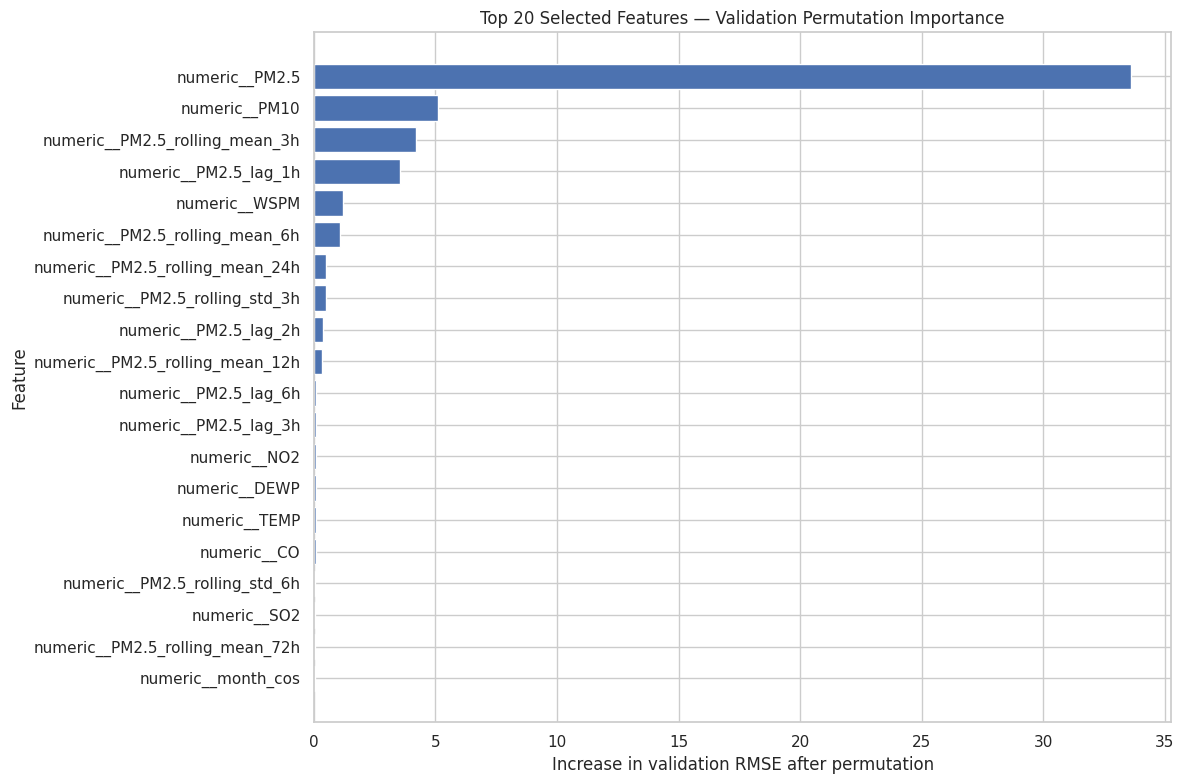

In [ ]:
# ==========================================
# PERMUTATION IMPORTANCE FOR THE SELECTED-FEATURE VALIDATION MODEL
# ==========================================

from sklearn.inspection import permutation_importance

validation_selected_features = best_feature_selector.transform(X_val_processed)
validation_feature_names = preprocessor.get_feature_names_out()[
    best_feature_selector.get_support()
]

# Use a reproducible sample for runtime efficiency.
importance_sample_size = min(5000, len(y_val))
rng = np.random.default_rng(RANDOM_STATE)
importance_indices = np.sort(
    rng.choice(len(y_val), size=importance_sample_size, replace=False)
)
X_importance_sample = validation_selected_features[importance_indices]
y_importance_sample = y_val.iloc[importance_indices]

perm_results = permutation_importance(
    best_feature_model,
    X_importance_sample,
    y_importance_sample,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

feature_importance_df = pd.DataFrame({
    "Feature": validation_feature_names,
    "Importance": perm_results.importances_mean,
    "Importance_Std": perm_results.importances_std
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("Permutation importance (validation sample):")
display(feature_importance_df.round(5))

top_features = feature_importance_df.head(20).sort_values("Importance")
plt.figure(figsize=(12, 8))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 20 Selected Features — Validation Permutation Importance")
plt.xlabel("Increase in validation RMSE after permutation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 19. Refit the selected model on train + validation, then evaluate once on test

After model and feature-count selection, refit the preprocessor and selector using train + validation. Fit the selected estimator on those transformed rows and evaluate on the untouched test period. The test results are for final reporting only, not for changing the selected model.

In [ ]:
# ==========================================
# FINAL REFIT: PREPROCESSOR + SELECTOR + MODEL
# ==========================================

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_regression

# Combine train and validation only after model/feature-count selection.
trainval_df = (
    pd.concat([train_df, val_df], axis=0)
    .sort_values(["target_datetime", "station"])
    .copy()
)
X_trainval = trainval_df[feature_columns].copy()
y_trainval = pd.to_numeric(trainval_df[TARGET], errors="coerce").astype("float64")
X_test_final = test_df[feature_columns].copy()
y_test_final = pd.to_numeric(test_df[TARGET], errors="coerce").astype("float64")

# Convert nullable pandas dtypes consistently before sklearn transforms.
for frame in [X_trainval, X_test_final]:
    for col in numeric_features:
        frame[col] = pd.to_numeric(frame[col], errors="coerce").astype("float64")
    for col in categorical_features:
        frame[col] = frame[col].astype("object")
        frame[col] = frame[col].where(frame[col].notna(), np.nan)

if not np.isfinite(y_trainval.to_numpy()).all():
    raise ValueError("Missing or infinite targets in train + validation data.")
if not np.isfinite(y_test_final.to_numpy()).all():
    raise ValueError("Missing or infinite targets in test data.")

# Refit preprocessor on train + validation; never fit on test.
final_preprocessor = clone(preprocessor)
X_trainval_processed = np.asarray(
    final_preprocessor.fit_transform(X_trainval), dtype=np.float32
)
X_test_processed = np.asarray(
    final_preprocessor.transform(X_test_final), dtype=np.float32
)

# Refit the validation-selected feature count on train + validation.
final_selector = SelectKBest(score_func=f_regression, k=best_k)
X_trainval_selected = final_selector.fit_transform(
    X_trainval_processed, y_trainval
)
X_test_selected = final_selector.transform(X_test_processed)

all_final_feature_names = final_preprocessor.get_feature_names_out()
final_selected_feature_names = all_final_feature_names[
    final_selector.get_support()
]

print("Selected model:", best_model_name)
print("Selected feature count:", best_k)
print("Train + validation matrix:", X_trainval_selected.shape)
print("Test matrix:", X_test_selected.shape)
print("Final selected features:")
for feature in final_selected_feature_names:
    print("-", feature)

# Final model: same model family selected on validation.
final_model = clone(model_templates[best_model_name])
final_model.fit(X_trainval_selected, y_trainval)

# Raw and non-negative forecasts.
test_predictions_raw = np.asarray(
    final_model.predict(X_test_selected), dtype=float
)
test_predictions_clipped = np.maximum(test_predictions_raw, 0)
test_predictions = test_predictions_clipped.copy()

# Full-test-set metrics for the selected model.
raw_test_metrics = regression_metrics(y_test_final, test_predictions_raw)
raw_test_metrics["Model"] = f"{best_model_name} (raw)"
raw_test_metrics["Rows scored"] = len(y_test_final)

final_test_metrics = regression_metrics(y_test_final, test_predictions_clipped)
final_test_metrics["Model"] = f"{best_model_name} + non-negative constraint"
final_test_metrics["Rows scored"] = len(y_test_final)

test_clipping_comparison = pd.DataFrame([raw_test_metrics, final_test_metrics])
print("FINAL TEST: RAW VS NON-NEGATIVE PREDICTIONS")
display(test_clipping_comparison.set_index("Model").round(4))
print("Negative raw predictions:", int((test_predictions_raw < 0).sum()))
print("Negative clipped predictions:", int((test_predictions_clipped < 0).sum()))

# Fair baseline comparison on the exact same test rows where current PM2.5 exists.
baseline_mask_test = test_df["PM2.5"].notna()
if not baseline_mask_test.any():
    raise ValueError("No test observations are available for the naive baseline comparison.")

test_baseline_metrics = regression_metrics(
    test_df.loc[baseline_mask_test, TARGET],
    test_df.loc[baseline_mask_test, "PM2.5"]
)
test_baseline_metrics["Model"] = "Naive baseline (current PM2.5)"
test_baseline_metrics["Rows scored"] = int(baseline_mask_test.sum())

same_rows_model_metrics = regression_metrics(
    y_test_final.loc[baseline_mask_test],
    test_predictions_clipped[baseline_mask_test.to_numpy()]
)
same_rows_model_metrics["Model"] = f"{best_model_name} + non-negative constraint"
same_rows_model_metrics["Rows scored"] = int(baseline_mask_test.sum())

test_comparison = pd.DataFrame([test_baseline_metrics, same_rows_model_metrics])
print("\nFINAL FAIR TEST COMPARISON — IDENTICAL ROWS")
display(test_comparison.set_index("Model").round(4))

print("\nFinal test rows:", len(y_test_final))
print("Fair baseline/model comparison rows:", int(baseline_mask_test.sum()))


Selected model: Extra Trees
Selected feature count: 30
Train + validation matrix: (360954, 30)
Test matrix: (51063, 30)
Final selected features:
- numeric__PM2.5
- numeric__PM10
- numeric__SO2
- numeric__NO2
- numeric__CO
- numeric__O3
- numeric__TEMP
- numeric__DEWP
- numeric__WSPM
- numeric__PM2.5_lag_1h
- numeric__PM2.5_lag_2h
- numeric__PM2.5_lag_3h
- numeric__PM2.5_lag_6h
- numeric__PM2.5_lag_12h
- numeric__PM2.5_lag_24h
- numeric__PM2.5_lag_48h
- numeric__PM2.5_rolling_mean_3h
- numeric__PM2.5_rolling_std_3h
- numeric__PM2.5_rolling_mean_6h
- numeric__PM2.5_rolling_std_6h
- numeric__PM2.5_rolling_mean_12h
- numeric__PM2.5_rolling_std_12h
- numeric__PM2.5_rolling_mean_24h
- numeric__PM2.5_rolling_std_24h
- numeric__PM2.5_rolling_mean_72h
- numeric__PM2.5_rolling_std_72h
- numeric__month_cos
- numeric__target_month_cos
- categorical__wd_NNW
- categorical__wd_NW
FINAL TEST: RAW VS NON-NEGATIVE PREDICTIONS


,MAE,RMSE,R2,Rows scored
Model,,,,
Extra Trees (raw),10.7698,21.3045,0.9535,51063
Extra Trees + non-negative constraint,10.7698,21.3045,0.9535,51063


Negative raw predictions: 0
Negative clipped predictions: 0

FINAL FAIR TEST COMPARISON — IDENTICAL ROWS


,MAE,RMSE,R2,Rows scored
Model,,,,
Naive baseline (current PM2.5),11.4957,22.9035,0.9465,50692
Extra Trees + non-negative constraint,10.6679,21.1200,0.9545,50692



Final test rows: 51063
Fair baseline/model comparison rows: 50692


## 20. Test comparison: all 75 features versus selected features

This is a descriptive final test-set comparison of the two pre-specified feature configurations. **Do not use these test results to change the selected feature count or model**; those decisions were made using validation data.

In [ ]:
# ==========================================
# TEST COMPARISON: ALL FEATURES VS SELECTED FEATURES
# ==========================================

full_feature_model = clone(model_templates[best_model_name])
full_feature_model.fit(X_trainval_processed, y_trainval)
full_predictions = np.maximum(
    np.asarray(full_feature_model.predict(X_test_processed), dtype=float), 0
)
selected_predictions = test_predictions_clipped.copy()

full_metrics = regression_metrics(y_test_final, full_predictions)
full_metrics.update({"Experiment": "All transformed features", "Number of Features": int(X_trainval_processed.shape[1])})
selected_metrics = regression_metrics(y_test_final, selected_predictions)
selected_metrics.update({"Experiment": "Validation-selected features", "Number of Features": int(best_k)})

final_feature_comparison = pd.DataFrame([full_metrics, selected_metrics])
print("FINAL TEST COMPARISON — REPORTING ONLY")
display(final_feature_comparison[[
    "Experiment", "Number of Features", "MAE", "RMSE", "R2"
]].round(4))


FINAL TEST COMPARISON — REPORTING ONLY


,Experiment,Number of Features,MAE,RMSE,R2
0,All transformed features,75,10.7196,21.1850,0.9541
1,Validation-selected features,30,10.7698,21.3045,0.9535


## 21. Final next-hour test forecasts and residual analysis

Use the clipped non-negative forecast as the primary output. Inspect actual versus predicted values, residual patterns and error distribution.

Final next-hour prediction dataset:


,station,datetime,target_datetime,PM2.5_next_1h,raw_prediction,prediction,residual,absolute_error
0,Aotizhongxin,2016-08-31 23:00:00,2016-09-01,7.0,9.667132,9.667132,-2.667132,2.667132
1,Changping,2016-08-31 23:00:00,2016-09-01,10.0,9.762462,9.762462,0.237538,0.237538
2,Dingling,2016-08-31 23:00:00,2016-09-01,8.0,12.013514,12.013514,-4.013514,4.013514
3,Dongsi,2016-08-31 23:00:00,2016-09-01,16.0,10.844569,10.844569,5.155431,5.155431
4,Guanyuan,2016-08-31 23:00:00,2016-09-01,6.0,10.751852,10.751852,-4.751852,4.751852


Total predictions: 51063
Negative final predictions: 0


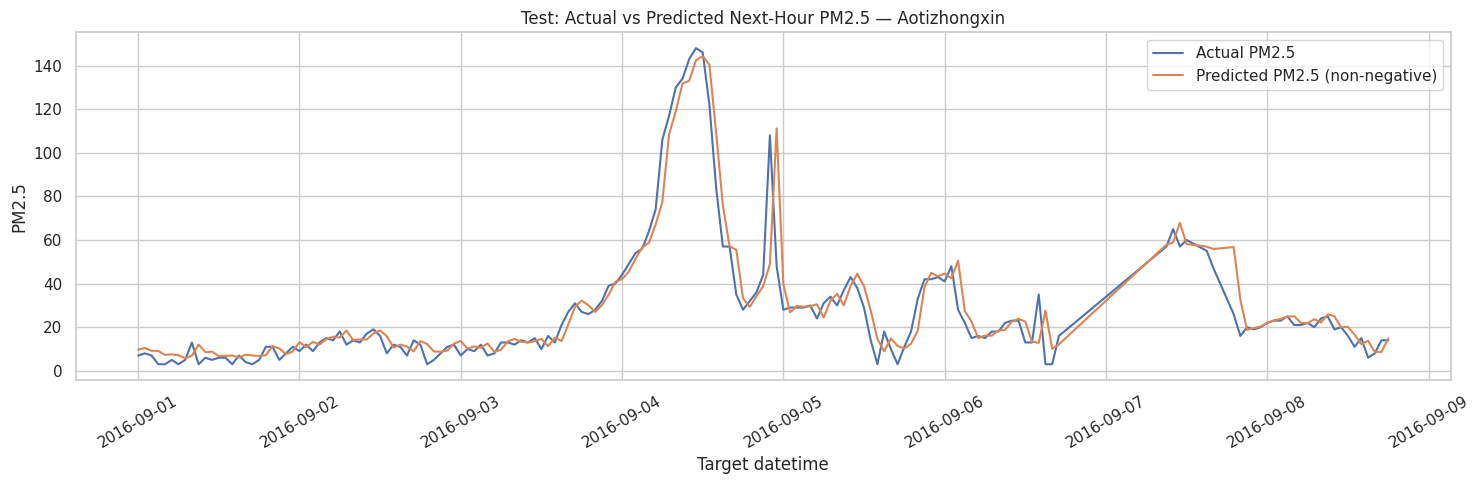

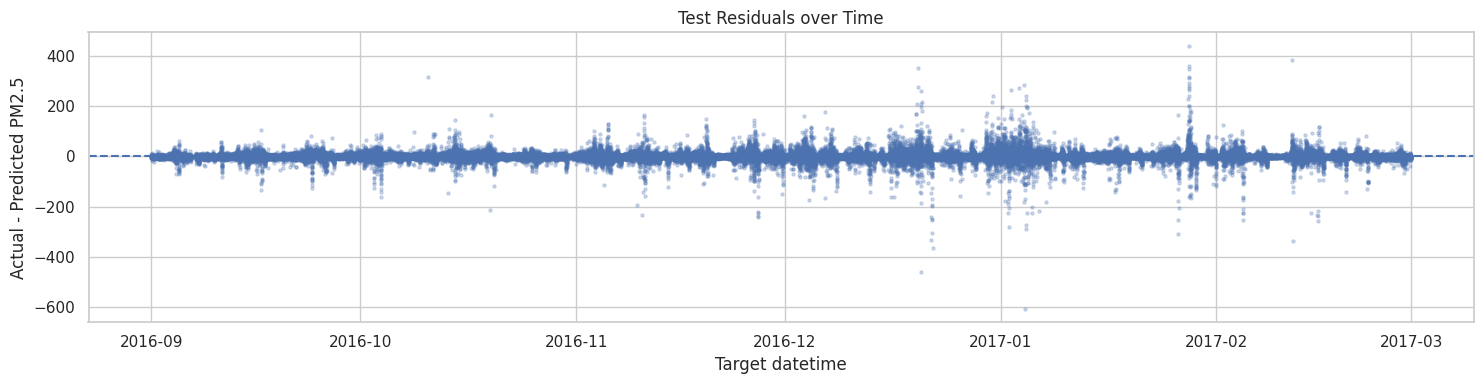

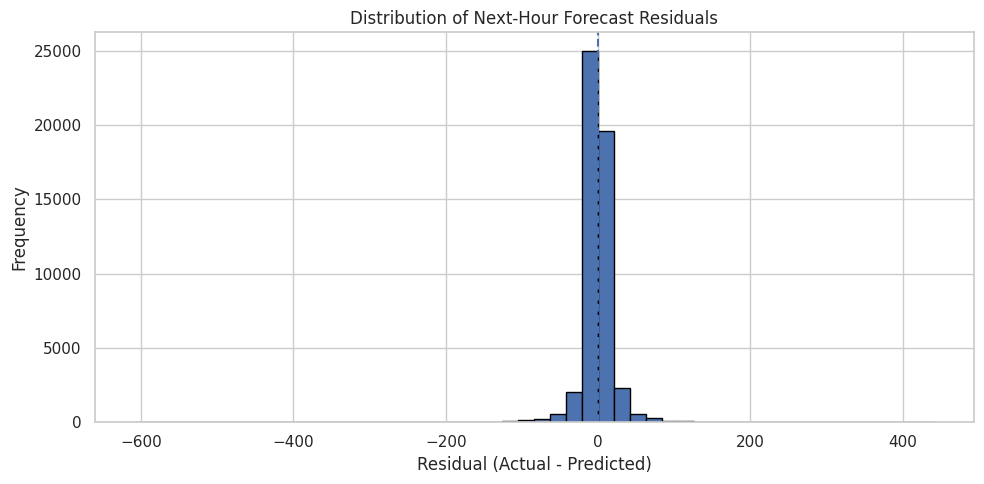

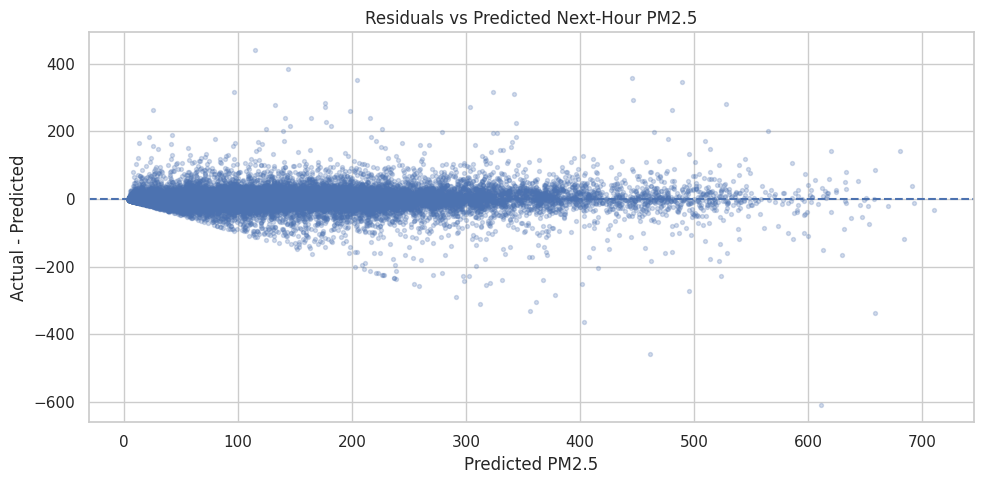

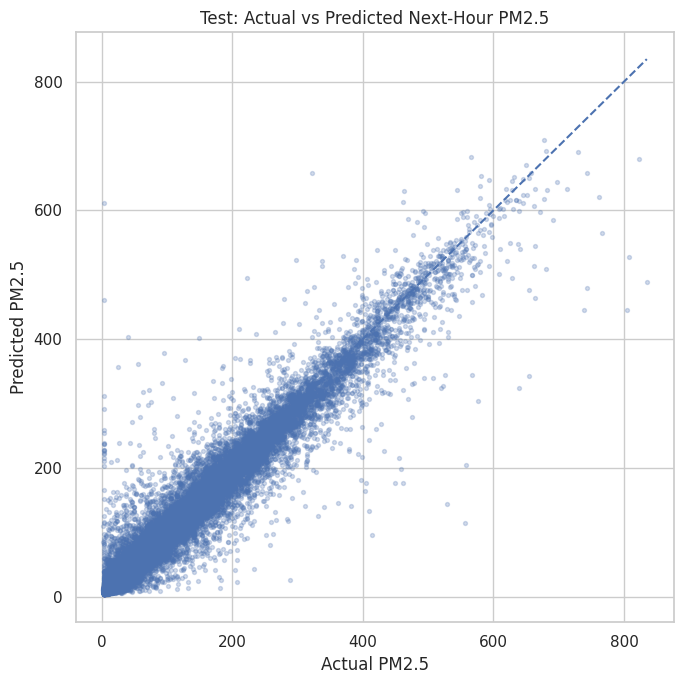

Overpredictions: 26945
Underpredictions: 24118
Exact predictions: 0
Mean residual: 0.0706


In [ ]:
# ==========================================
# FINAL NEXT-HOUR TEST PREDICTIONS
# ==========================================

test_predictions_df = test_df[
    ["station", "datetime", "target_datetime", TARGET]
].copy().reset_index(drop=True)

test_predictions_df["raw_prediction"] = test_predictions_raw
test_predictions_df["prediction"] = test_predictions_clipped

test_predictions_df["residual"] = (
    test_predictions_df[TARGET]
    - test_predictions_df["prediction"]
)
test_predictions_df["absolute_error"] = (
    test_predictions_df["residual"].abs()
)

assert len(test_predictions_df) == len(test_predictions_clipped)
assert (test_predictions_df["prediction"] >= 0).all()

print("Final next-hour prediction dataset:")
display(test_predictions_df.head())
print("Total predictions:", len(test_predictions_df))
print(
    "Negative final predictions:",
    int((test_predictions_df["prediction"] < 0).sum())
)

# Actual vs predicted for one station, first 7 days of test period.
PLOT_STATION = sorted(test_predictions_df["station"].unique())[0]
station_test_plot = (
    test_predictions_df[
        test_predictions_df["station"] == PLOT_STATION
    ]
    .sort_values("target_datetime")
    .head(24 * 7)
)

plt.figure(figsize=(15, 5))
plt.plot(
    station_test_plot["target_datetime"],
    station_test_plot[TARGET],
    label="Actual PM2.5"
)
plt.plot(
    station_test_plot["target_datetime"],
    station_test_plot["prediction"],
    label="Predicted PM2.5 (non-negative)"
)
plt.title(
    f"Test: Actual vs Predicted Next-Hour PM2.5 — {PLOT_STATION}"
)
plt.xlabel("Target datetime")
plt.ylabel("PM2.5")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Residuals over time.
plt.figure(figsize=(15, 4))
plt.scatter(
    test_predictions_df["target_datetime"],
    test_predictions_df["residual"],
    s=5,
    alpha=0.25
)
plt.axhline(0, linestyle="--")
plt.title("Test Residuals over Time")
plt.xlabel("Target datetime")
plt.ylabel("Actual - Predicted PM2.5")
plt.tight_layout()
plt.show()

# Residual distribution.
plt.figure(figsize=(10, 5))
plt.hist(
    test_predictions_df["residual"],
    bins=50,
    edgecolor="black"
)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Next-Hour Forecast Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Residuals versus predictions.
plt.figure(figsize=(10, 5))
plt.scatter(
    test_predictions_df["prediction"],
    test_predictions_df["residual"],
    s=8,
    alpha=0.25
)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted Next-Hour PM2.5")
plt.xlabel("Predicted PM2.5")
plt.ylabel("Actual - Predicted")
plt.tight_layout()
plt.show()

# Actual versus predicted scatter.
plt.figure(figsize=(7, 7))
plt.scatter(
    test_predictions_df[TARGET],
    test_predictions_df["prediction"],
    s=8,
    alpha=0.25
)
axis_min = min(
    test_predictions_df[TARGET].min(),
    test_predictions_df["prediction"].min()
)
axis_max = max(
    test_predictions_df[TARGET].max(),
    test_predictions_df["prediction"].max()
)
plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--"
)
plt.title("Test: Actual vs Predicted Next-Hour PM2.5")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.tight_layout()
plt.show()


# Overall directional error summary.
over_predictions = int((test_predictions_df["residual"] < 0).sum())
under_predictions = int((test_predictions_df["residual"] > 0).sum())
perfect_predictions = int((test_predictions_df["residual"] == 0).sum())
print("Overpredictions:", over_predictions)
print("Underpredictions:", under_predictions)
print("Exact predictions:", perfect_predictions)
print("Mean residual:", round(test_predictions_df["residual"].mean(), 4))


## 22. Station-wise test performance and error by pollution level

Evaluate MAE, RMSE and R² separately for each station and across quantile groups of the actual PM2.5 target. These are descriptive test-set analyses; do not use them to retune the model.

TEST PERFORMANCE BY MONITORING STATION


,MAE,RMSE,R2,Rows
Station,,,,
Dingling,9.3169,18.3588,0.9446,4143
Huairou,8.9600,19.7440,0.9414,4280
Wanliu,10.1264,20.0828,0.9572,4288
Aotizhongxin,10.7312,20.2164,0.9587,4292
Changping,10.9888,20.3021,0.9442,4297
Tiantan,10.9578,20.4715,0.9584,4284
Shunyi,10.9744,21.1769,0.9536,4210
Guanyuan,11.5313,21.6247,0.9536,4248
Nongzhanguan,11.1534,22.0839,0.9560,4260


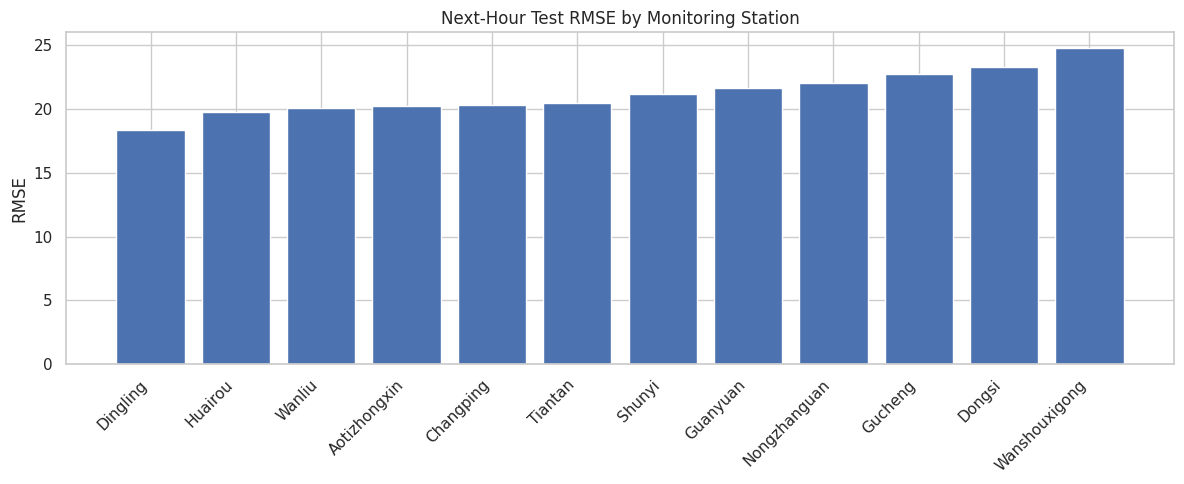

TEST FORECAST PERFORMANCE BY ACTUAL PM2.5 LEVEL


,PM2.5_Level,Records,Actual_PM25_Mean,Predicted_PM25_Mean,Mean_Residual,MAE,RMSE
0,"(1.999, 13.0]",10392,8.175,11.724,-3.549,4.472,14.483
1,"(13.0, 37.0]",10257,23.200,25.456,-2.256,6.434,12.497
2,"(37.0, 84.0]",10020,59.524,61.659,-2.135,9.714,17.938
3,"(84.0, 159.0]",10220,118.107,117.183,0.924,12.590,19.945
4,"(159.0, 835.0]",10174,253.633,246.205,7.428,20.786,34.493


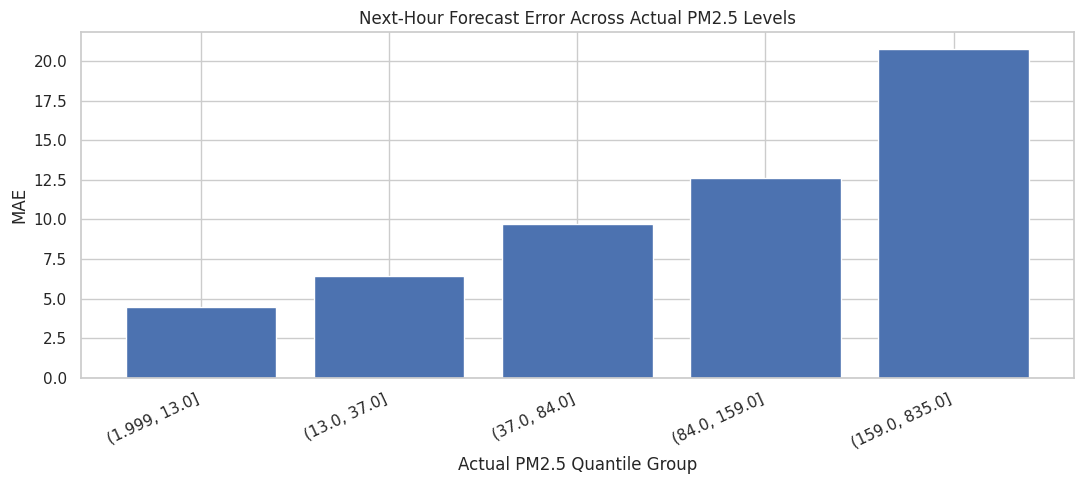

In [ ]:
# ==========================================
# STATION-WISE TEST PERFORMANCE
# ==========================================

station_metrics = []

for station_name, part in test_predictions_df.groupby("station"):
    metrics = regression_metrics(
        part[TARGET],
        part["prediction"]
    )
    metrics["Station"] = station_name
    metrics["Rows"] = len(part)
    station_metrics.append(metrics)

station_metrics_df = (
    pd.DataFrame(station_metrics)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("TEST PERFORMANCE BY MONITORING STATION")
display(
    station_metrics_df.set_index("Station").round(4)
)

plt.figure(figsize=(12, 5))
plt.bar(
    station_metrics_df["Station"],
    station_metrics_df["RMSE"]
)
plt.title("Next-Hour Test RMSE by Monitoring Station")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ==========================================
# ERROR ANALYSIS BY ACTUAL PM2.5 LEVEL
# ==========================================

error_analysis_df = test_predictions_df.copy()

error_analysis_df["PM2.5_Level"] = pd.qcut(
    error_analysis_df[TARGET],
    q=5,
    duplicates="drop"
)

quantile_error_analysis = (
    error_analysis_df
    .groupby("PM2.5_Level", observed=True)
    .agg(
        Records=("residual", "size"),
        Actual_PM25_Mean=(TARGET, "mean"),
        Predicted_PM25_Mean=("prediction", "mean"),
        Mean_Residual=("residual", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("residual", lambda x: np.sqrt(np.mean(x ** 2))),
    )
    .reset_index()
)

print("TEST FORECAST PERFORMANCE BY ACTUAL PM2.5 LEVEL")
display(quantile_error_analysis.round(3))

plt.figure(figsize=(11, 5))
plt.bar(
    quantile_error_analysis["PM2.5_Level"].astype(str),
    quantile_error_analysis["MAE"]
)
plt.title("Next-Hour Forecast Error Across Actual PM2.5 Levels")
plt.xlabel("Actual PM2.5 Quantile Group")
plt.ylabel("MAE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 23. Final selected-feature model interpretation

Permutation importance below was calculated on validation data using the model trained on the training partition. It is descriptive and does not establish causality.

In [ ]:
print("Final selected transformed input features:")
for feature in final_selected_feature_names:
    print(feature)

print("\nSelected model:", best_model_name)
print("Selected feature count:", best_k)
print("Final test MAE:", round(final_test_metrics["MAE"], 4))
print("Final test RMSE:", round(final_test_metrics["RMSE"], 4))
print("Final test R2:", round(final_test_metrics["R2"], 4))


Final selected transformed input features:
numeric__PM2.5
numeric__PM10
numeric__SO2
numeric__NO2
numeric__CO
numeric__O3
numeric__TEMP
numeric__DEWP
numeric__WSPM
numeric__PM2.5_lag_1h
numeric__PM2.5_lag_2h
numeric__PM2.5_lag_3h
numeric__PM2.5_lag_6h
numeric__PM2.5_lag_12h
numeric__PM2.5_lag_24h
numeric__PM2.5_lag_48h
numeric__PM2.5_rolling_mean_3h
numeric__PM2.5_rolling_std_3h
numeric__PM2.5_rolling_mean_6h
numeric__PM2.5_rolling_std_6h
numeric__PM2.5_rolling_mean_12h
numeric__PM2.5_rolling_std_12h
numeric__PM2.5_rolling_mean_24h
numeric__PM2.5_rolling_std_24h
numeric__PM2.5_rolling_mean_72h
numeric__PM2.5_rolling_std_72h
numeric__month_cos
numeric__target_month_cos
categorical__wd_NNW
categorical__wd_NW

Selected model: Extra Trees
Selected feature count: 30
Final test MAE: 10.7698
Final test RMSE: 21.3045
Final test R2: 0.9535


## 24. Save the final next-hour model and forecasting outputs

Save the complete inference chain: raw input feature order, preprocessing transformer, feature selector, estimator and non-negative output rule. Save all comparison tables and diagnostics in the dedicated one-hour output folder.

In [ ]:
# ==========================================
# SAVE FINAL 1-HOUR FORECASTING ARTIFACTS
# ==========================================

import joblib

OUTPUT_DIR = DATA_DIR / "forecasting_outputs_1h"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export prepared data and test forecasts.
model_df.to_csv(TARGET_PREPARED_PATH, index=False)
test_predictions_df.to_csv(OUTPUT_DIR / "test_forecasts_1h.csv", index=False)

# Export model-selection and evaluation tables.
model_comparison.to_csv(OUTPUT_DIR / "validation_model_comparison_1h.csv", index=False)
comparison_with_baseline.to_csv(OUTPUT_DIR / "validation_with_baseline_1h.csv", index=False)
feature_selection_comparison.to_csv(OUTPUT_DIR / "validation_feature_selection_1h.csv", index=False)
comparison_summary.to_csv(OUTPUT_DIR / "validation_full_vs_selected_features_1h.csv", index=False)
feature_importance_df.to_csv(OUTPUT_DIR / "validation_permutation_importance_1h.csv", index=False)
test_clipping_comparison.to_csv(OUTPUT_DIR / "test_raw_vs_clipped_1h.csv", index=False)
test_comparison.to_csv(OUTPUT_DIR / "test_fair_baseline_comparison_1h.csv", index=False)
final_feature_comparison.to_csv(OUTPUT_DIR / "test_full_vs_selected_features_1h.csv", index=False)
station_metrics_df.to_csv(OUTPUT_DIR / "test_metrics_by_station_1h.csv", index=False)
quantile_error_analysis.to_csv(OUTPUT_DIR / "test_error_by_pollution_level_1h.csv", index=False)

# Save every component required for future inference.
model_bundle = {
    "forecast_horizon_hours": int(HORIZON_HOURS),
    "target_column": TARGET,
    "feature_columns": list(feature_columns),
    "numeric_features": list(numeric_features),
    "categorical_features": list(categorical_features),
    "model_name": best_model_name,
    "selected_k": int(best_k),
    "selected_feature_names": list(final_selected_feature_names),
    "preprocessor": final_preprocessor,
    "feature_selector": final_selector,
    "model": final_model,
    "non_negative_output": True,
}

model_path = OUTPUT_DIR / "pm25_next_hour_forecasting_model.joblib"
joblib.dump(model_bundle, model_path)

# Save a reproducibility summary.
run_summary = {
    "forecast_horizon_hours": int(HORIZON_HOURS),
    "target_column": TARGET,
    "selected_model_by_validation": best_model_name,
    "selected_feature_count_by_validation": int(best_k),
    "selected_features": list(final_selected_feature_names),
    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "train_validation_rows": int(len(y_trainval)),
    "test_rows": int(len(test_df)),
    "test_metrics_all_rows_non_negative": {
        key: float(final_test_metrics[key]) for key in ["MAE", "RMSE", "R2"]
    },
    "test_metrics_raw": {
        key: float(raw_test_metrics[key]) for key in ["MAE", "RMSE", "R2"]
    },
    "fair_baseline_comparison_rows": int(baseline_mask_test.sum()),
}

with open(OUTPUT_DIR / "run_summary_1h.json", "w", encoding="utf-8") as file:
    json.dump(run_summary, file, indent=2)

print("Saved final 1-hour forecasting outputs to:", OUTPUT_DIR)
print("Saved model bundle:", model_path)
for saved_path in sorted(OUTPUT_DIR.glob("*")):
    if saved_path.is_file():
        print(f"- {saved_path.name}: {saved_path.stat().st_size / (1024**2):.2f} MB")


Saved final 1-hour forecasting outputs to: /content/drive/MyDrive/DSA/Major Project/DataSet/forecasting_outputs_1h
Saved model bundle: /content/drive/MyDrive/DSA/Major Project/DataSet/forecasting_outputs_1h/pm25_next_hour_forecasting_model.joblib
- pm25_next_hour_forecasting_model.joblib: 547.62 MB
- run_summary_1h.json: 0.00 MB
- test_error_by_pollution_level_1h.csv: 0.00 MB
- test_fair_baseline_comparison_1h.csv: 0.00 MB
- test_fair_model_comparison_1h.csv: 0.00 MB
- test_forecasts_1h.csv: 6.28 MB
- test_full_vs_selected_features_1h.csv: 0.00 MB
- test_metrics_by_station_1h.csv: 0.00 MB
- test_raw_vs_clipped_1h.csv: 0.00 MB
- validation_feature_selection_1h.csv: 0.00 MB
- validation_full_vs_selected_features_1h.csv: 0.00 MB
- validation_model_comparison_1h.csv: 0.00 MB
- validation_permutation_importance_1h.csv: 0.00 MB
- validation_with_baseline_1h.csv: 0.00 MB


## 25. Final project interpretation checklist

Before reporting results, confirm:

- The forecast target is `PM2.5_next_1h`.
- Each target belongs to the same station exactly one hour after the input observation.
- Lag and rolling predictors use only current or historical measurements.
- Future calendar values are used only because they are known in advance.
- Train, validation and test periods are chronological and split by target time.
- Imputation, scaling and encoding are fitted on training only for validation experiments.
- Feature selection is fitted on training only for validation experiments.
- The final preprocessor and selector are refitted on train + validation, never on test.
- Model and feature-count selection use validation results, not test results.
- The final model bundle includes the preprocessor, selector and estimator.
- Naive baseline and selected model are compared on identical test observations.
- Predictions are constrained to be non-negative; report this as post-processing.
- Test metrics, station-level performance and pollution-level errors are reported honestly.

**Interpretation note:** Feature selection used `SelectKBest(f_regression)`, which scores each transformed feature individually with a univariate linear F-test. This is not a proof of causal influence and can miss nonlinear interactions.
